# How Much Does the Standard Evaluation Protocol Inflate Credit Card Fraud Detection Results?

A rolling-origin and external-validation study on the ULB European-cardholder
credit card dataset.

The pipeline below deduplicates the data, splits it, handles class imbalance
three ways, tunes and benchmarks three classifiers, and then asks two questions
that the conventional protocol cannot answer:

- **Protocol optimism.** How much AUPRC does a random stratified split add
  relative to a deployment-realistic out-of-time split, measured across
  several rolling cut-offs with prevalence-matched comparison arms?
- **Selection transfer.** Does the imbalance-handling strategy chosen on this
  benchmark remain the best choice on an independently authored dataset under
  a temporal protocol with a label-availability delay?

Primary metric is AUPRC throughout. ROC-AUC, precision, recall, F1, Brier
score and an example-dependent cost model are reported alongside it.

> **Submission build.** Complete run, all sections consistent. The only change
> since your last run is the reference list, which now includes the works cited
> in the text; no cell needs to be re-run.


In [ ]:
import os
import sys
import time
import glob
import platform
import warnings
import urllib.request
import urllib.error

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats as scipy_stats
from scipy.stats import loguniform, randint, uniform as sp_uniform

import sklearn
from sklearn.model_selection import (
    StratifiedKFold, RepeatedStratifiedKFold, train_test_split,
    RandomizedSearchCV, cross_val_predict,
)
from sklearn.preprocessing import RobustScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    average_precision_score, precision_recall_curve, roc_auc_score, roc_curve,
    precision_score, recall_score, f1_score, confusion_matrix,
    classification_report, brier_score_loss,
)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    from imblearn.over_sampling import SMOTE
    from imblearn.under_sampling import RandomUnderSampler
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

SEARCH_BUDGET_MODE = "full"
TUNE_SAMPLE_SIZE = 40000
N_TUNE_ITER = 8 if SEARCH_BUDGET_MODE == "fast" else 30
TUNE_CV_FOLDS = 3

N_BOOTSTRAP = 500
N_ROBUSTNESS_SEEDS = 5

REVIEW_COST_USD = 5.0
COST_REVIEW_GRID = [1.0, 2.0, 5.0, 10.0, 20.0, 50.0]
N_COST_THRESHOLDS = 199

TEMPORAL_TRAIN_FRACTION = 0.70

EXTERNAL_DATA_MODE = "handbook"
HANDBOOK_N_DAYS = 92
IEEE_CIS_PATH = ""
DELAY_DAYS = 7

META_CALIBRATION = "sigmoid"

GLOBAL_START = time.time()
train_times = {}
best_params = {}

mpl.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "font.size": 11,
    "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 10,
    "figure.figsize": (6.0, 4.0),
})
sns.set_style("whitegrid")

print("Python        :", sys.version.split()[0])
print("Platform      :", platform.platform())
print("CPU cores     :", os.cpu_count())
print("NumPy         :", np.__version__)
print("Pandas        :", pd.__version__)
print("scikit-learn  :", sklearn.__version__)
print("XGBoost avail :", HAS_XGB)
print("imblearn avail:", HAS_IMBLEARN)
print("Random seed   :", RANDOM_STATE)

Python        : 3.13.15
Platform      : Linux-6.6.122+-x86_64-with-glibc2.39
CPU cores     : 2
NumPy         : 2.1.3
Pandas        : 2.2.3
scikit-learn  : 1.6.1
XGBoost avail : True
imblearn avail: True
Random seed   : 42


## Data acquisition

The notebook expects `creditcard.csv` at `My Drive/Research/Journal 2/` when
run in Colab, and falls back to the working directory otherwise.

In [ ]:
DRIVE_RELATIVE_PATH = "Research/Journal 2/creditcard.csv"
LOCAL_FALLBACK_PATH = "creditcard.csv"


def load_dataset():
    try:
        import google.colab
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        path = os.path.join("/content/drive/MyDrive", DRIVE_RELATIVE_PATH)
        if os.path.exists(path):
            print(f"Loaded dataset from Google Drive: {path}")
            return pd.read_csv(path)
        print(f"WARNING: file not found at '{path}'.")
    except ImportError:
        pass

    if os.path.exists(LOCAL_FALLBACK_PATH):
        print(f"Loaded dataset from local path: {LOCAL_FALLBACK_PATH}")
        return pd.read_csv(LOCAL_FALLBACK_PATH)

    raise FileNotFoundError(
        "creditcard.csv not found. In Colab place it at "
        f"'My Drive/{DRIVE_RELATIVE_PATH}'; locally place it at "
        f"'{LOCAL_FALLBACK_PATH}'."
    )


df_raw = load_dataset()
print("Raw shape:", df_raw.shape)
df_raw.head()

Mounted at /content/drive
Loaded dataset from Google Drive: /content/drive/MyDrive/Research/Journal 2/creditcard.csv
Raw shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Data integrity and deduplication

Exact duplicate rows are a documented artifact of this dataset and are removed
before any split, so no duplicated transaction can appear in both the training
and test sets.

In [ ]:
print("Missing values in the whole frame:", int(df_raw.isnull().sum().sum()))
print("\nColumn dtypes:")
print(df_raw.dtypes.value_counts())

dup_mask = df_raw.duplicated()
n_dup = int(dup_mask.sum())
n_dup_fraud = int(df_raw.loc[dup_mask, "Class"].sum())

print(f"\nDuplicate rows found: {n_dup} "
      f"({n_dup - n_dup_fraud} genuine, {n_dup_fraud} fraud)")

df = df_raw.drop_duplicates().reset_index(drop=True)

print(f"\nRows before deduplication: {len(df_raw):,}")
print(f"Rows after  deduplication: {len(df):,}")
print(f"Rows removed             : {len(df_raw) - len(df):,} "
      f"({(len(df_raw) - len(df)) / len(df_raw) * 100:.3f}%)")
print(f"Fraud count before/after : {int(df_raw['Class'].sum())} -> "
      f"{int(df['Class'].sum())}")

Missing values in the whole frame: 0

Column dtypes:
float64    30
int64       1
Name: count, dtype: int64

Duplicate rows found: 1081 (1062 genuine, 19 fraud)

Rows before deduplication: 284,807
Rows after  deduplication: 283,726
Rows removed             : 1,081 (0.380%)
Fraud count before/after : 492 -> 473


Class distribution after deduplication
      Class  Count  Percentage (%)
Genuine (0) 283253          99.833
  Fraud (1)    473           0.167


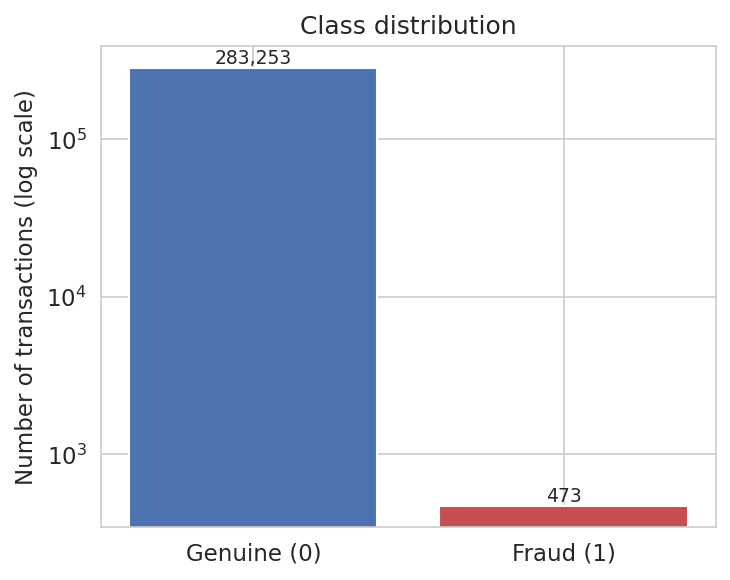


Imbalance ratio (genuine:fraud) = 598.8 : 1


In [ ]:
class_counts = df["Class"].value_counts().sort_index()
class_table = pd.DataFrame({
    "Class": ["Genuine (0)", "Fraud (1)"],
    "Count": class_counts.values,
    "Percentage (%)": (class_counts / len(df) * 100).round(3).values,
})
print("Class distribution after deduplication")
print(class_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(class_table["Class"], class_table["Count"], color=["#4C72B0", "#C44E52"])
ax.set_yscale("log")
ax.set_ylabel("Number of transactions (log scale)")
ax.set_title("Class distribution")
for i, v in enumerate(class_table["Count"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("class_distribution.png", bbox_inches="tight")
plt.show()

imbalance_ratio = class_counts[0] / class_counts[1]
print(f"\nImbalance ratio (genuine:fraud) = {imbalance_ratio:.1f} : 1")

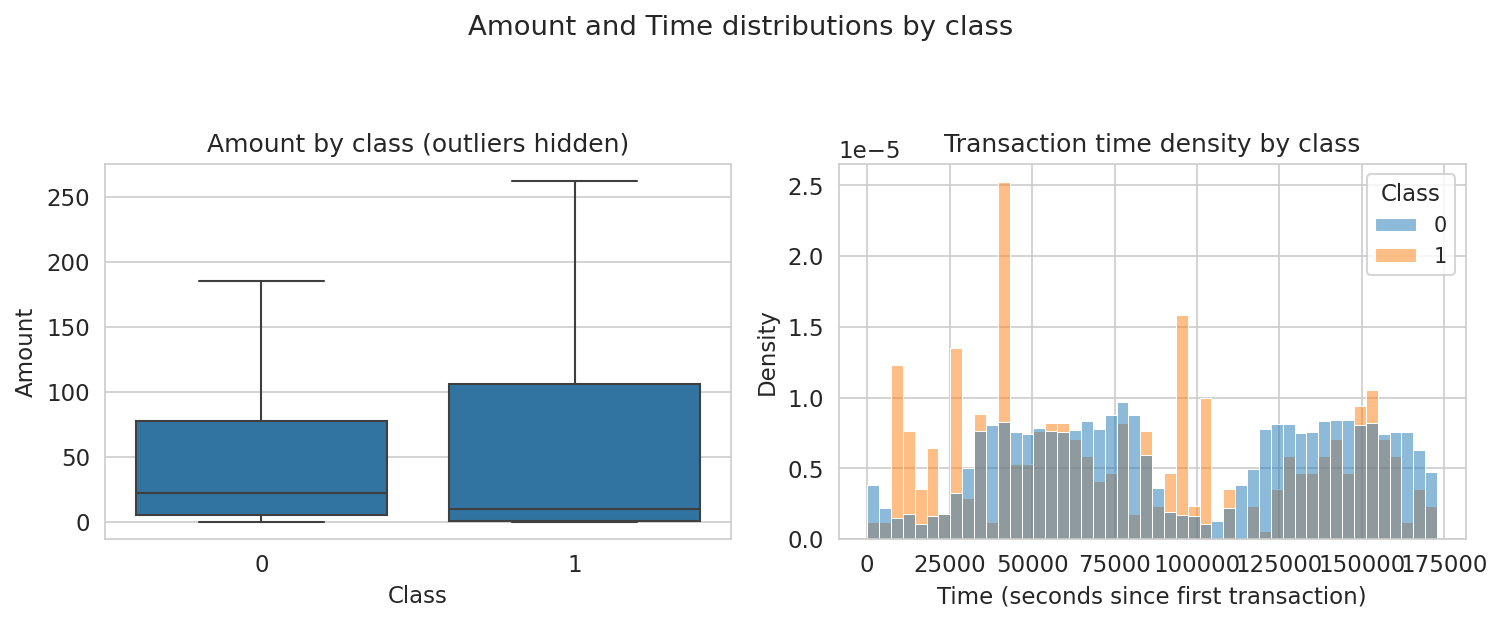

Summary statistics of Amount by class
          count    mean  median     std       max
Class                                            
0      283253.0   88.41   22.00  250.38  25691.16
1         473.0  123.87    9.82  260.21   2125.87


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(x="Class", y="Amount", data=df, ax=axes[0], showfliers=False)
axes[0].set_title("Amount by class (outliers hidden)")

sns.histplot(data=df, x="Time", hue="Class", stat="density", common_norm=False,
             bins=48, ax=axes[1])
axes[1].set_title("Transaction time density by class")
axes[1].set_xlabel("Time (seconds since first transaction)")

plt.suptitle("Amount and Time distributions by class", y=1.03)
plt.tight_layout()
plt.savefig("amount_time_distributions.png", bbox_inches="tight")
plt.show()

amount_stats = (df.groupby("Class")["Amount"]
                  .describe()[["count", "mean", "50%", "std", "max"]]
                  .rename(columns={"50%": "median"}).round(2))
print("Summary statistics of Amount by class")
print(amount_stats.to_string())

MEAN_FRAUD_AMOUNT = float(df.loc[df["Class"] == 1, "Amount"].mean())

## Preprocessing

`V1`-`V28` are already PCA components. `Time` and `Amount` are scaled with a
`RobustScaler` that is fitted on the training split only; the unscaled matrix
is kept so that every later protocol which re-splits the data refits its own
scaler on its own training rows.

In [ ]:
X = df.drop(columns=["Class"]).copy()
y = df["Class"].copy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

SCALE_COLS = ["Time", "Amount"]


def fit_apply_scaler(X_tr_raw, X_te_raw, cols=None):
    cols = [c for c in (cols or SCALE_COLS) if c in X_tr_raw.columns]
    sc = RobustScaler().fit(X_tr_raw[cols])
    X_tr, X_te = X_tr_raw.copy(), X_te_raw.copy()
    X_tr[cols] = sc.transform(X_tr_raw[cols])
    X_te[cols] = sc.transform(X_te_raw[cols])
    return X_tr, X_te, sc


X_train, X_test, scaler = fit_apply_scaler(X_train_raw, X_test_raw)

amount_train_raw = X_train_raw["Amount"].to_numpy()
amount_test_raw = X_test_raw["Amount"].to_numpy()

print("Train set:", X_train.shape, f" | fraud rate: {y_train.mean() * 100:.4f}%")
print("Test set :", X_test.shape, f" | fraud rate: {y_test.mean() * 100:.4f}%")

leaky_scaler = RobustScaler().fit(X[SCALE_COLS])
audit_df = pd.DataFrame({
    "Centre (train-only, used)": scaler.center_,
    "Centre (full-data, leaky)": leaky_scaler.center_,
    "Scale (train-only, used)": scaler.scale_,
    "Scale (full-data, leaky)": leaky_scaler.scale_,
}, index=SCALE_COLS)
audit_df["Centre shift (%)"] = 100 * (audit_df.iloc[:, 1] - audit_df.iloc[:, 0]) / \
                               audit_df.iloc[:, 0].replace(0, np.nan)
audit_df["Scale shift (%)"] = 100 * (audit_df.iloc[:, 3] - audit_df.iloc[:, 2]) / \
                              audit_df.iloc[:, 2]

print("\nPreprocessing provenance audit")
print(audit_df.round(4).to_string())
print("Test-set rows used to estimate any preprocessing parameter: NONE")

Train set: (198608, 30)  | fraud rate: 0.1667%
Test set : (85118, 30)  | fraud rate: 0.1668%

Preprocessing provenance audit
        Centre (train-only, used)  Centre (full-data, leaky)  Scale (train-only, used)  Scale (full-data, leaky)  Centre shift (%)  Scale shift (%)
Time                     84857.00                    84692.5                  85098.50                  85093.25           -0.1939          -0.0062
Amount                      22.08                       22.0                     72.01                     71.91           -0.3623          -0.1389
Test-set rows used to estimate any preprocessing parameter: NONE


In [ ]:
def build_strategy_training_set(X_tr, y_tr, strategy, seed):
    if strategy in ("class_weight", "class_weight_tuned"):
        return X_tr, y_tr
    if strategy == "undersampling":
        return RandomUnderSampler(random_state=seed).fit_resample(X_tr, y_tr)
    if strategy == "smote":
        return SMOTE(random_state=seed).fit_resample(X_tr, y_tr)
    raise ValueError(f"Unknown strategy: {strategy}")


def instantiate_like(strategy, name, y_ref, seed):
    use_weight = strategy in ("class_weight", "class_weight_tuned")
    cw = "balanced" if use_weight else None
    tuned = (strategy == "class_weight_tuned") and (name in best_params)

    if name == "LogisticRegression":
        params = {"class_weight": cw, "max_iter": 1000, "random_state": seed}
        if tuned:
            params.update(best_params[name])
        return LogisticRegression(**params)

    if name == "RandomForest":
        params = {"class_weight": cw, "n_jobs": -1, "random_state": seed,
                  "n_estimators": 200}
        if tuned:
            params.update(best_params[name])
        return RandomForestClassifier(**params)

    if name == "XGBoost":
        if use_weight:
            neg, pos = np.bincount(np.asarray(y_ref))
            spw = neg / pos
        else:
            spw = 1
        params = {"n_estimators": 300, "max_depth": 5, "learning_rate": 0.1,
                  "scale_pos_weight": spw, "eval_metric": "aucpr",
                  "random_state": seed, "n_jobs": -1}
        if tuned:
            params.update(best_params[name])
            params["scale_pos_weight"] = spw
        return XGBClassifier(**params)

    raise ValueError(f"Unknown model: {name}")


print("Strategy and estimator helpers defined.")

Strategy and estimator helpers defined.


## Class-imbalance handling

Three strategies are applied to the training set only: class weighting,
random undersampling of the majority class, and SMOTE oversampling of the
minority class.

In [ ]:
resampled_sets = {"class_weight": (X_train, y_train)}

if HAS_IMBLEARN:
    X_rus, y_rus = RandomUnderSampler(random_state=RANDOM_STATE).fit_resample(
        X_train, y_train)
    resampled_sets["undersampling"] = (X_rus, y_rus)

    X_smote, y_smote = SMOTE(random_state=RANDOM_STATE).fit_resample(
        X_train, y_train)
    resampled_sets["smote"] = (X_smote, y_smote)

    print("Resampled training set sizes:")
    for name, (Xr, yr) in resampled_sets.items():
        print(f"  {name:14s}: n={len(yr):,}  fraud rate={yr.mean() * 100:.2f}%")
else:
    print("imbalanced-learn not installed; only class-weighting will run.")

Resampled training set sizes:
  class_weight  : n=198,608  fraud rate=0.17%
  undersampling : n=662  fraud rate=50.00%
  smote         : n=396,554  fraud rate=50.00%


## Model training

Logistic Regression, Random Forest and XGBoost are benchmarked under every
imbalance strategy with near-default hyperparameters, then tuned with an
equal, audited search budget per model family.

In [ ]:
def make_models(strategy, y_ref):
    use_weight = strategy == "class_weight"
    cw = "balanced" if use_weight else None

    models = {
        "LogisticRegression": LogisticRegression(
            class_weight=cw, max_iter=1000, random_state=RANDOM_STATE),
        "RandomForest": RandomForestClassifier(
            n_estimators=200, class_weight=cw, n_jobs=-1,
            random_state=RANDOM_STATE),
    }
    if HAS_XGB:
        if use_weight:
            neg, pos = np.bincount(np.asarray(y_ref))
            spw = neg / pos
        else:
            spw = 1
        models["XGBoost"] = XGBClassifier(
            n_estimators=300, max_depth=5, learning_rate=0.1,
            scale_pos_weight=spw, eval_metric="aucpr",
            random_state=RANDOM_STATE, n_jobs=-1)
    return models


trained_models = {}

for strategy, (Xr, yr) in resampled_sets.items():
    for name, clf in make_models(strategy, yr).items():
        t0 = time.time()
        clf.fit(Xr, yr)
        elapsed = time.time() - t0
        trained_models[(strategy, name)] = clf
        train_times[(strategy, name)] = elapsed
        print(f"[{strategy:14s}] {name:20s} trained in {elapsed:7.2f}s")

[class_weight  ] LogisticRegression   trained in    2.68s
[class_weight  ] RandomForest         trained in  176.48s
[class_weight  ] XGBoost              trained in    7.25s
[undersampling ] LogisticRegression   trained in    0.02s
[undersampling ] RandomForest         trained in    0.81s
[undersampling ] XGBoost              trained in    1.36s
[smote         ] LogisticRegression   trained in    5.02s
[smote         ] RandomForest         trained in  608.70s
[smote         ] XGBoost              trained in   16.20s


In [ ]:
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train, train_size=min(TUNE_SAMPLE_SIZE, len(X_train)),
    stratify=y_train, random_state=RANDOM_STATE,
)

print(f"Search budget mode        : {SEARCH_BUDGET_MODE}")
print(f"Hyperparameter subsample  : {len(X_tune):,} rows "
      f"(fraud rate {y_tune.mean() * 100:.3f}%)")
print(f"Sampled configs / family  : {N_TUNE_ITER}")
print(f"Inner CV folds / family   : {TUNE_CV_FOLDS}")
print(f"Candidate fits / family   : {N_TUNE_ITER * TUNE_CV_FOLDS}")
print(f"Scoring                   : average_precision\n")

search_spaces = {
    "LogisticRegression": (
        LogisticRegression(class_weight="balanced", max_iter=1000,
                           random_state=RANDOM_STATE),
        {"C": loguniform(1e-3, 1e2), "solver": ["lbfgs", "liblinear"]},
    ),
    "RandomForest": (
        RandomForestClassifier(class_weight="balanced", n_jobs=-1,
                               random_state=RANDOM_STATE),
        {"n_estimators": randint(100, 400), "max_depth": randint(4, 20),
         "min_samples_leaf": randint(1, 10),
         "max_features": ["sqrt", "log2", None]},
    ),
}
if HAS_XGB:
    neg_tune, pos_tune = np.bincount(y_tune)
    search_spaces["XGBoost"] = (
        XGBClassifier(scale_pos_weight=neg_tune / pos_tune, eval_metric="aucpr",
                      random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": randint(100, 400), "max_depth": randint(3, 10),
         "learning_rate": sp_uniform(0.01, 0.29),
         "subsample": sp_uniform(0.6, 0.4),
         "colsample_bytree": sp_uniform(0.6, 0.4)},
    )

search_budget_records = []

for name, (estimator, param_dist) in search_spaces.items():
    t0 = time.time()
    search = RandomizedSearchCV(
        estimator, param_distributions=param_dist, n_iter=N_TUNE_ITER,
        scoring="average_precision", cv=TUNE_CV_FOLDS,
        random_state=RANDOM_STATE, n_jobs=-1, refit=True,
    )
    search.fit(X_tune, y_tune)
    best_params[name] = search.best_params_
    search_time = time.time() - t0

    n_candidates = len(search.cv_results_["params"])
    cv_scores = np.asarray(search.cv_results_["mean_test_score"], dtype=float)

    print(f"{name:20s} best inner-CV AUPRC = {search.best_score_:.4f} "
          f"| search time {search_time:6.1f}s")
    print(f"{'':20s} candidates: {n_candidates} x {TUNE_CV_FOLDS} folds = "
          f"{n_candidates * TUNE_CV_FOLDS} fits")
    print(f"{'':20s} AUPRC across candidates: min={np.nanmin(cv_scores):.4f}, "
          f"median={np.nanmedian(cv_scores):.4f}, max={np.nanmax(cv_scores):.4f}")
    print(f"{'':20s} best params: {search.best_params_}")

    tuned_estimator = search.best_estimator_.__class__(**{
        **search.best_estimator_.get_params(), **search.best_params_
    })
    t0 = time.time()
    tuned_estimator.fit(X_train, y_train)
    refit_time = time.time() - t0
    trained_models[("class_weight_tuned", name)] = tuned_estimator
    train_times[("class_weight_tuned", name)] = refit_time
    print(f"{'':20s} refit on the full training set in {refit_time:.1f}s\n")

    search_budget_records.append({
        "Model family": name,
        "Sampled configs": n_candidates,
        "Inner CV folds": TUNE_CV_FOLDS,
        "Total candidate fits": n_candidates * TUNE_CV_FOLDS,
        "Search wall time (s)": round(search_time, 1),
        "Best inner-CV AUPRC": round(float(search.best_score_), 4),
        "Worst candidate AUPRC": round(float(np.nanmin(cv_scores)), 4),
        "Refit time (s)": round(refit_time, 1),
    })

search_budget_df = pd.DataFrame(search_budget_records)
print("Hyperparameter search budget per model family")
print(search_budget_df.to_string(index=False))

if search_budget_df["Total candidate fits"].nunique() == 1:
    print(f"\nBudget parity check: PASS - every family received "
          f"{search_budget_df['Total candidate fits'].iloc[0]} candidate fits.")
else:
    print("\nBudget parity check: FAIL - budgets differ across families.")

Search budget mode        : full
Hyperparameter subsample  : 40,000 rows (fraud rate 0.168%)
Sampled configs / family  : 30
Inner CV folds / family   : 3
Candidate fits / family   : 90
Scoring                   : average_precision

LogisticRegression   best inner-CV AUPRC = 0.7693 | search time   26.2s
                     candidates: 30 x 3 folds = 90 fits
                     AUPRC across candidates: min=0.6908, median=0.7609, max=0.7693
                     best params: {'C': np.float64(3.4702669886504163), 'solver': 'liblinear'}
                     refit on the full training set in 3.6s

RandomForest         best inner-CV AUPRC = 0.8186 | search time 2059.3s
                     candidates: 30 x 3 folds = 90 fits
                     AUPRC across candidates: min=0.7097, median=0.7465, max=0.8186
                     best params: {'max_depth': 11, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 147}
                     refit on the full training set in 103.8s

XGBoo

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {name: [] for name in make_models("class_weight", y_train)}

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    for name, clf in make_models("class_weight", y_tr).items():
        clf.fit(X_tr, y_tr)
        auprc = average_precision_score(y_val, clf.predict_proba(X_val)[:, 1])
        cv_results[name].append(auprc)
        print(f"Fold {fold} | {name:20s} AUPRC = {auprc:.4f}")

cv_summary = pd.DataFrame({
    "Model": list(cv_results.keys()),
    "Mean AUPRC": [np.mean(v) for v in cv_results.values()],
    "Std AUPRC": [np.std(v) for v in cv_results.values()],
})
print("\nFive-fold cross-validation AUPRC (class weighting, default hyperparameters)")
print(cv_summary.round(4).to_string(index=False))

Fold 1 | LogisticRegression   AUPRC = 0.6597
Fold 1 | RandomForest         AUPRC = 0.8206
Fold 1 | XGBoost              AUPRC = 0.8155
Fold 2 | LogisticRegression   AUPRC = 0.7802
Fold 2 | RandomForest         AUPRC = 0.8627
Fold 2 | XGBoost              AUPRC = 0.8777
Fold 3 | LogisticRegression   AUPRC = 0.7017
Fold 3 | RandomForest         AUPRC = 0.8088
Fold 3 | XGBoost              AUPRC = 0.8222
Fold 4 | LogisticRegression   AUPRC = 0.7766
Fold 4 | RandomForest         AUPRC = 0.8694
Fold 4 | XGBoost              AUPRC = 0.8809
Fold 5 | LogisticRegression   AUPRC = 0.7817
Fold 5 | RandomForest         AUPRC = 0.8648
Fold 5 | XGBoost              AUPRC = 0.8796

Five-fold cross-validation AUPRC (class weighting, default hyperparameters)
             Model  Mean AUPRC  Std AUPRC
LogisticRegression      0.7400     0.0502
      RandomForest      0.8453     0.0253
           XGBoost      0.8552     0.0298


In [ ]:
model_names = list(cv_results.keys())
ALPHA = 0.05
sig_rows = []

for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        a_name, b_name = model_names[i], model_names[j]
        a, b = np.array(cv_results[a_name]), np.array(cv_results[b_name])

        t_stat, t_p = scipy_stats.ttest_rel(a, b)
        try:
            w_stat, w_p = scipy_stats.wilcoxon(a, b)
        except ValueError:
            w_p = np.nan

        sig_rows.append({
            "Comparison": f"{a_name} vs {b_name}",
            "Mean AUPRC diff": round(a.mean() - b.mean(), 4),
            "Paired t-test p": round(float(t_p), 4),
            "Wilcoxon p": round(float(w_p), 4) if not np.isnan(w_p) else np.nan,
            "Significant (t-test, a=0.05)": bool(t_p < ALPHA),
        })

sig_df = pd.DataFrame(sig_rows)
print("Pairwise significance of AUPRC differences across the five shared folds")
print(sig_df.to_string(index=False))
print("\nWith n=5 paired folds these p-values have limited power and should be "
      "read alongside the effect sizes, not instead of them.")

Pairwise significance of AUPRC differences across the five shared folds
                        Comparison  Mean AUPRC diff  Paired t-test p  Wilcoxon p  Significant (t-test, a=0.05)
LogisticRegression vs RandomForest          -0.1053           0.0020      0.0625                          True
     LogisticRegression vs XGBoost          -0.1152           0.0005      0.0625                          True
           RandomForest vs XGBoost          -0.0099           0.0591      0.1250                         False

With n=5 paired folds these p-values have limited power and should be read alongside the effect sizes, not instead of them.


## Held-out test set evaluation

AUPRC is the primary metric. ROC-AUC, precision, recall and F1 at the default
0.5 threshold are reported for every strategy and model combination, including
the tuned models.

In [ ]:
records = []
roc_pr_curves = {}
test_proba_store = {}

for (strategy, name), clf in trained_models.items():
    proba = clf.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    test_proba_store[(strategy, name)] = proba
    cm = confusion_matrix(y_test, pred)

    records.append({
        "Strategy": strategy, "Model": name,
        "AUPRC": average_precision_score(y_test, proba),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1],
    })

    p, r, thr = precision_recall_curve(y_test, proba)
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_pr_curves[(strategy, name)] = {"pr": (p, r, thr), "roc": (fpr, tpr)}

results_df = (pd.DataFrame(records)
                .sort_values("AUPRC", ascending=False)
                .reset_index(drop=True))
print("Test-set performance across all strategy and model combinations")
print(results_df.round(4).to_string(index=False))

best_row = results_df.iloc[0]
best_strategy, best_name = best_row["Strategy"], best_row["Model"]
best_clf = trained_models[(best_strategy, best_name)]
print(f"\nBest configuration by AUPRC: {best_name} / {best_strategy} "
      f"(AUPRC = {best_row['AUPRC']:.4f})")

Test-set performance across all strategy and model combinations
          Strategy              Model  AUPRC  ROC-AUC  Precision  Recall  F1-score    TN   FP  FN  TP
class_weight_tuned            XGBoost 0.8334   0.9749     0.9483  0.7746    0.8527 84970    6  32 110
      class_weight       RandomForest 0.8221   0.9378     0.9619  0.7113    0.8178 84972    4  41 101
      class_weight            XGBoost 0.8179   0.9631     0.9083  0.7676    0.8321 84965   11  33 109
             smote       RandomForest 0.8152   0.9739     0.9145  0.7535    0.8263 84966   10  35 107
class_weight_tuned       RandomForest 0.7973   0.9665     0.8833  0.7465    0.8092 84962   14  36 106
             smote            XGBoost 0.7869   0.9677     0.7285  0.7746    0.7509 84935   41  32 110
class_weight_tuned LogisticRegression 0.6897   0.9663     0.0528  0.8873    0.0996 82715 2261  16 126
             smote LogisticRegression 0.6888   0.9656     0.0515  0.8803    0.0974 82675 2301  17 125
      class_weight

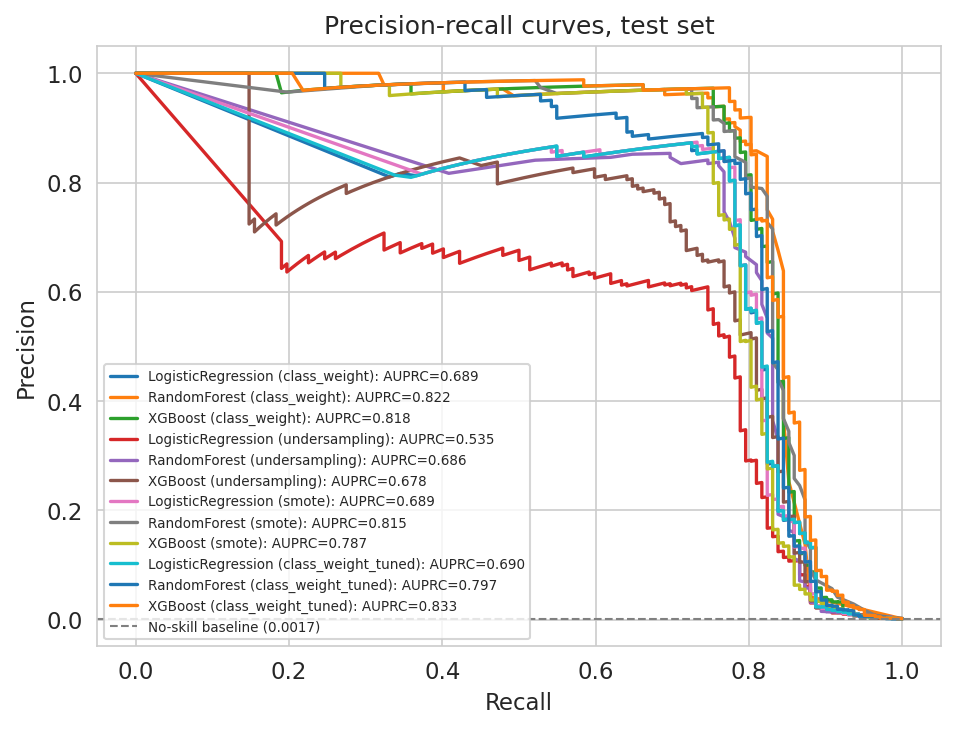

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5))
no_skill = y_test.mean()

for (strategy, name), curves in roc_pr_curves.items():
    p, r, _ = curves["pr"]
    auprc = results_df.loc[(results_df["Strategy"] == strategy) &
                           (results_df["Model"] == name), "AUPRC"].values[0]
    ax.plot(r, p, lw=1.6, label=f"{name} ({strategy}): AUPRC={auprc:.3f}")

ax.axhline(no_skill, color="grey", linestyle="--", lw=1,
           label=f"No-skill baseline ({no_skill:.4f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curves, test set")
ax.legend(fontsize=6.5, loc="lower left")
plt.tight_layout()
plt.savefig("precision_recall_curves.png", bbox_inches="tight")
plt.show()

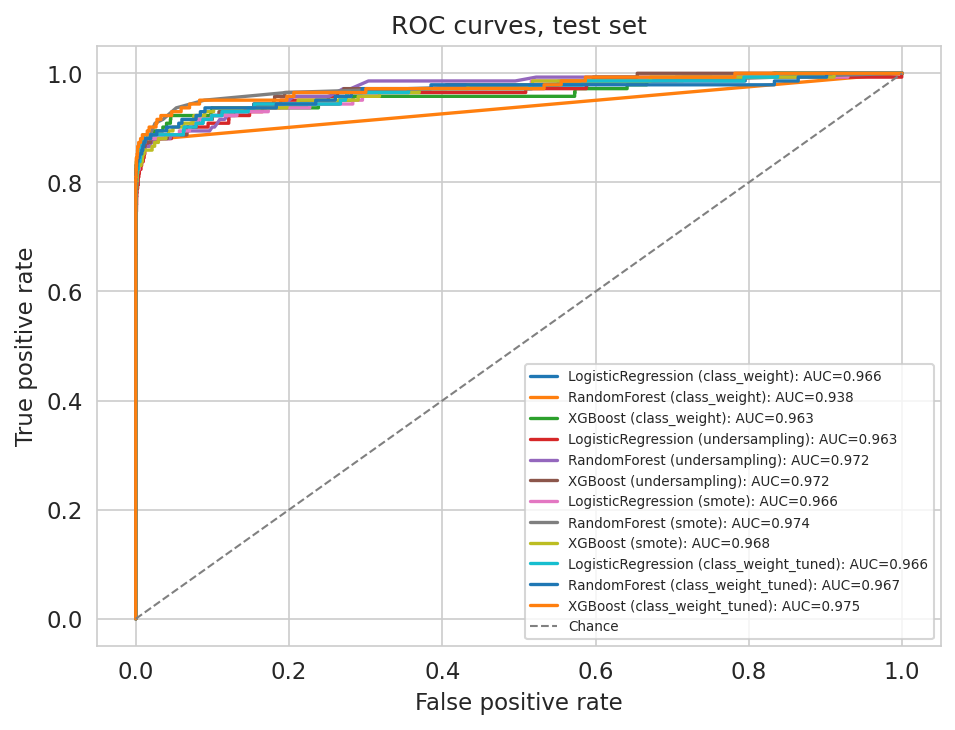

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5))

for (strategy, name), curves in roc_pr_curves.items():
    fpr, tpr = curves["roc"]
    roc_auc = results_df.loc[(results_df["Strategy"] == strategy) &
                             (results_df["Model"] == name), "ROC-AUC"].values[0]
    ax.plot(fpr, tpr, lw=1.6, label=f"{name} ({strategy}): AUC={roc_auc:.3f}")

ax.plot([0, 1], [0, 1], color="grey", linestyle="--", lw=1, label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves, test set")
ax.legend(fontsize=6.5, loc="lower right")
plt.tight_layout()
plt.savefig("roc_curves.png", bbox_inches="tight")
plt.show()

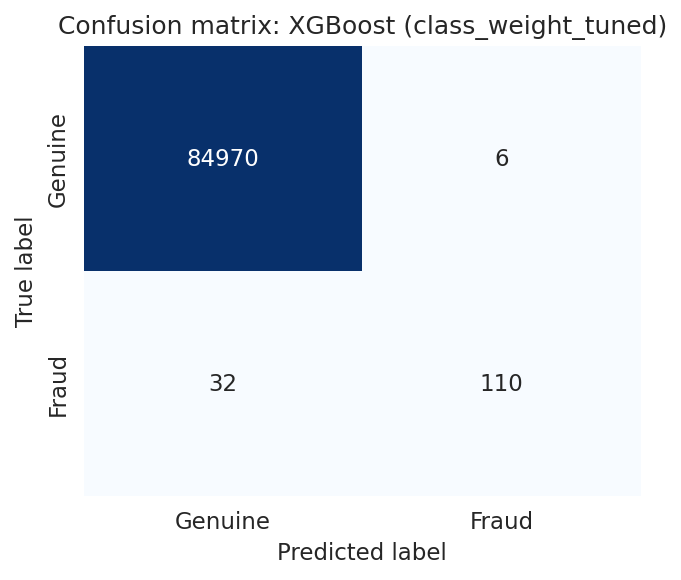

Classification report at threshold 0.5
              precision    recall  f1-score   support

     Genuine     0.9996    0.9999    0.9998     84976
       Fraud     0.9483    0.7746    0.8527       142

    accuracy                         0.9996     85118
   macro avg     0.9739    0.8873    0.9262     85118
weighted avg     0.9995    0.9996    0.9995     85118



In [ ]:
proba_best = test_proba_store[(best_strategy, best_name)]
pred_best = (proba_best >= 0.5).astype(int)
cm_best = confusion_matrix(y_test, pred_best)

fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm_best, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Genuine", "Fraud"], yticklabels=["Genuine", "Fraud"],
            cbar=False, ax=ax)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title(f"Confusion matrix: {best_name} ({best_strategy})")
plt.tight_layout()
plt.savefig("confusion_matrix_best_model.png", bbox_inches="tight")
plt.show()

print("Classification report at threshold 0.5")
print(classification_report(y_test, pred_best,
                            target_names=["Genuine", "Fraud"], digits=4))

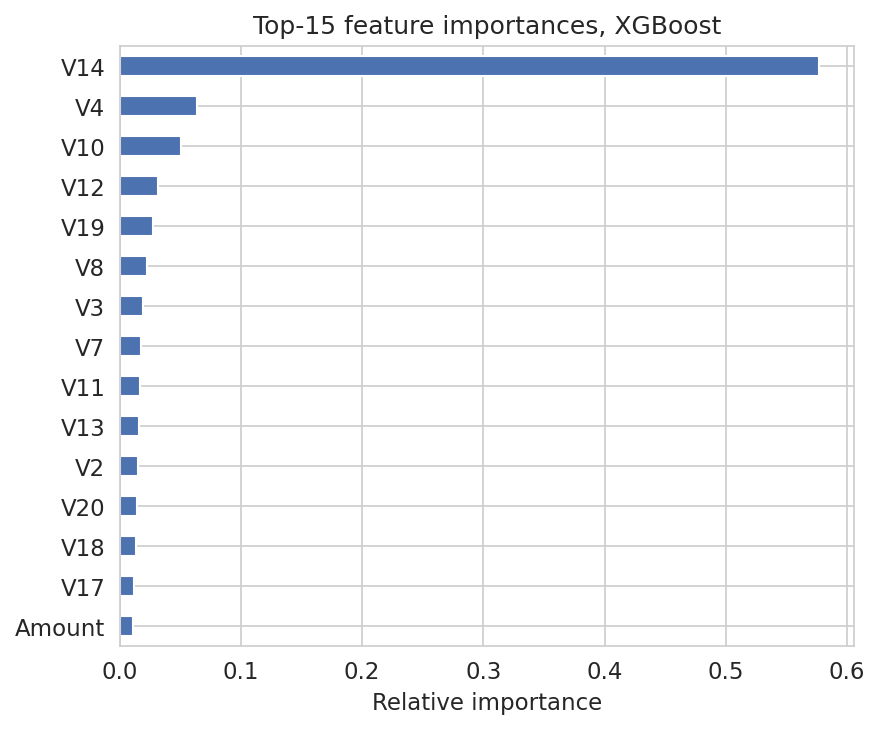

In [ ]:
if hasattr(best_clf, "feature_importances_"):
    importances = pd.Series(best_clf.feature_importances_, index=X.columns)
    top15 = importances.sort_values(ascending=False).head(15)

    fig, ax = plt.subplots(figsize=(6, 5))
    top15.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
    ax.set_xlabel("Relative importance")
    ax.set_title(f"Top-15 feature importances, {best_name}")
    plt.tight_layout()
    plt.savefig("feature_importance.png", bbox_inches="tight")
    plt.show()
else:
    print(f"{best_name} does not expose feature_importances_; use permutation "
          f"importance or SHAP for this model family.")

In [ ]:
rng = np.random.RandomState(RANDOM_STATE)
y_test_arr = y_test.to_numpy()
n_test = len(y_test_arr)
bootstrap_rows = []

for (strategy, name), proba in test_proba_store.items():
    auprc_samples = np.empty(N_BOOTSTRAP)
    roc_samples = np.empty(N_BOOTSTRAP)

    for b in range(N_BOOTSTRAP):
        idx = rng.randint(0, n_test, n_test)
        y_bs, p_bs = y_test_arr[idx], proba[idx]
        if y_bs.sum() == 0 or y_bs.sum() == len(y_bs):
            auprc_samples[b] = np.nan
            roc_samples[b] = np.nan
            continue
        auprc_samples[b] = average_precision_score(y_bs, p_bs)
        roc_samples[b] = roc_auc_score(y_bs, p_bs)

    auprc_samples = auprc_samples[~np.isnan(auprc_samples)]
    roc_samples = roc_samples[~np.isnan(roc_samples)]

    bootstrap_rows.append({
        "Strategy": strategy, "Model": name,
        "AUPRC mean": auprc_samples.mean(),
        "AUPRC 95% CI low": np.percentile(auprc_samples, 2.5),
        "AUPRC 95% CI high": np.percentile(auprc_samples, 97.5),
        "ROC-AUC mean": roc_samples.mean(),
        "ROC-AUC 95% CI low": np.percentile(roc_samples, 2.5),
        "ROC-AUC 95% CI high": np.percentile(roc_samples, 97.5),
    })

bootstrap_df = (pd.DataFrame(bootstrap_rows)
                  .sort_values("AUPRC mean", ascending=False)
                  .reset_index(drop=True))
print(f"Bootstrap 95% confidence intervals ({N_BOOTSTRAP} resamples of the test set)")
print(bootstrap_df.round(4).to_string(index=False))

Bootstrap 95% confidence intervals (500 resamples of the test set)
          Strategy              Model  AUPRC mean  AUPRC 95% CI low  AUPRC 95% CI high  ROC-AUC mean  ROC-AUC 95% CI low  ROC-AUC 95% CI high
class_weight_tuned            XGBoost      0.8313            0.7635             0.8878        0.9747              0.9552               0.9901
      class_weight       RandomForest      0.8229            0.7608             0.8812        0.9386              0.9113               0.9624
      class_weight            XGBoost      0.8181            0.7574             0.8760        0.9626              0.9388               0.9834
             smote       RandomForest      0.8145            0.7465             0.8754        0.9741              0.9555               0.9895
class_weight_tuned       RandomForest      0.7994            0.7368             0.8539        0.9669              0.9441               0.9853
             smote            XGBoost      0.7874            0.7248             0

In [ ]:
robustness_rows = []
robustness_seeds = [RANDOM_STATE + i for i in range(N_ROBUSTNESS_SEEDS)]

print(f"Repeating {best_name} / {best_strategy} across {N_ROBUSTNESS_SEEDS} "
      f"independent splits: {robustness_seeds}\n")

for seed in robustness_seeds:
    t0 = time.time()
    Xtr_raw_s, Xte_raw_s, ytr_s, yte_s = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=seed)
    Xtr_s, Xte_s, _ = fit_apply_scaler(Xtr_raw_s, Xte_raw_s)
    Xr_s, yr_s = build_strategy_training_set(Xtr_s, ytr_s, best_strategy, seed)
    clf_s = instantiate_like(best_strategy, best_name, yr_s, seed)
    clf_s.fit(Xr_s, yr_s)

    proba_s = clf_s.predict_proba(Xte_s)[:, 1]
    pred_s = (proba_s >= 0.5).astype(int)
    robustness_rows.append({
        "Seed": seed,
        "AUPRC": average_precision_score(yte_s, proba_s),
        "ROC-AUC": roc_auc_score(yte_s, proba_s),
        "F1-score": f1_score(yte_s, pred_s, zero_division=0),
        "Fit time (s)": time.time() - t0,
    })
    print(f"Seed {seed}: AUPRC={robustness_rows[-1]['AUPRC']:.4f}  "
          f"ROC-AUC={robustness_rows[-1]['ROC-AUC']:.4f}  "
          f"F1={robustness_rows[-1]['F1-score']:.4f}")

robustness_df = pd.DataFrame(robustness_rows)
print(f"\nMulti-seed robustness of {best_name} / {best_strategy} "
      f"over {N_ROBUSTNESS_SEEDS} independent splits")
print(robustness_df[["AUPRC", "ROC-AUC", "F1-score"]]
      .agg(["mean", "std"]).round(4).to_string())

Repeating XGBoost / class_weight_tuned across 5 independent splits: [42, 43, 44, 45, 46]

Seed 42: AUPRC=0.8323  ROC-AUC=0.9688  F1=0.8682
Seed 43: AUPRC=0.8691  ROC-AUC=0.9856  F1=0.8978
Seed 44: AUPRC=0.8643  ROC-AUC=0.9780  F1=0.8806
Seed 45: AUPRC=0.8689  ROC-AUC=0.9805  F1=0.8832
Seed 46: AUPRC=0.8401  ROC-AUC=0.9785  F1=0.8864

Multi-seed robustness of XGBoost / class_weight_tuned over 5 independent splits
       AUPRC  ROC-AUC  F1-score
mean  0.8550   0.9783    0.8833
std   0.0174   0.0061    0.0107


F2-optimal threshold = 0.1888 (F2 = 0.8237)
              precision    recall  f1-score   support

     Genuine     0.9997    0.9999    0.9998     84976
       Fraud     0.9194    0.8028    0.8571       142

    accuracy                         0.9996     85118
   macro avg     0.9595    0.9013    0.9285     85118
weighted avg     0.9995    0.9996    0.9995     85118


Cost-optimal threshold under the fixed-scalar model = 0.010 (cost $3,386.80 versus $3,993.90 at 0.5)
              precision    recall  f1-score   support

     Genuine     0.9997    0.9993    0.9995     84976
       Fraud     0.6686    0.8239    0.7382       142

    accuracy                         0.9990     85118
   macro avg     0.8341    0.9116    0.8688     85118
weighted avg     0.9992    0.9990    0.9991     85118



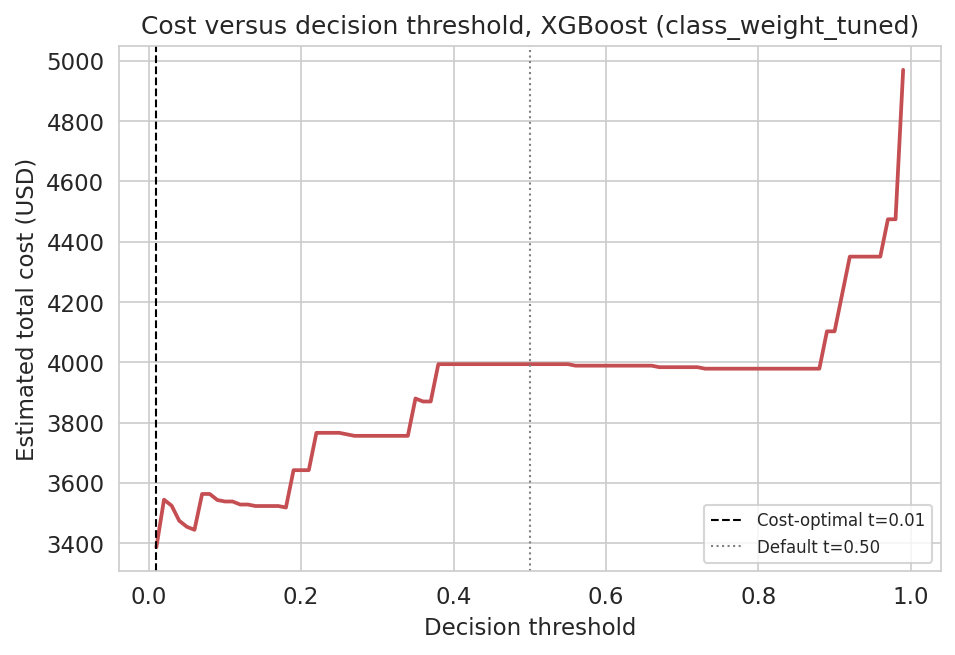

In [ ]:
p_curve, r_curve, thr_curve = roc_pr_curves[(best_strategy, best_name)]["pr"]

f2_scores = (5 * p_curve[:-1] * r_curve[:-1]) / \
            (4 * p_curve[:-1] + r_curve[:-1] + 1e-12)
f2_best_idx = int(np.nanargmax(f2_scores))
f2_threshold = float(thr_curve[f2_best_idx])

print(f"F2-optimal threshold = {f2_threshold:.4f} "
      f"(F2 = {f2_scores[f2_best_idx]:.4f})")
print(classification_report(y_test, (proba_best >= f2_threshold).astype(int),
                            target_names=["Genuine", "Fraud"], digits=4))

candidate_thresholds = np.linspace(0.01, 0.99, 99)
costs = []
for t in candidate_thresholds:
    tn, fp, fn, tp = confusion_matrix(
        y_test, (proba_best >= t).astype(int)).ravel()
    costs.append(fp * REVIEW_COST_USD + fn * MEAN_FRAUD_AMOUNT)

costs = np.array(costs)
cost_best_idx = int(np.argmin(costs))
cost_threshold = float(candidate_thresholds[cost_best_idx])

print(f"\nCost-optimal threshold under the fixed-scalar model = {cost_threshold:.3f} "
      f"(cost ${costs[cost_best_idx]:,.2f} versus "
      f"${costs[int(np.argmin(np.abs(candidate_thresholds - 0.5)))]:,.2f} at 0.5)")
print(classification_report(y_test, (proba_best >= cost_threshold).astype(int),
                            target_names=["Genuine", "Fraud"], digits=4))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(candidate_thresholds, costs, lw=1.8, color="#C44E52")
ax.axvline(cost_threshold, color="black", linestyle="--", lw=1,
           label=f"Cost-optimal t={cost_threshold:.2f}")
ax.axvline(0.5, color="grey", linestyle=":", lw=1, label="Default t=0.50")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Estimated total cost (USD)")
ax.set_title(f"Cost versus decision threshold, {best_name} ({best_strategy})")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("cost_vs_threshold.png", bbox_inches="tight")
plt.show()

## Out-of-time validation and the Time-feature ablation

Every table above rests on a random stratified split. That is the convention
in published work on this dataset but it is not the deployment condition: a
production system is fitted on the past and scored on the future. The same
winning configuration is therefore run under four protocols, crossing the
split rule with the presence of the `Time` column.

Out-of-time cut-off at Time = 132,906s (36.9h into the 48h window)
  train (earlier): 198,608 rows, 366 frauds (0.1843%)
  test  (later)  : 85,118 rows, 107 frauds (0.1257%)
  The fraud rate itself differs across the cut-off, which is real non-stationarity that a random split averages away.

[Random split      | with Time   ] AUPRC=0.8323  ROC-AUC=0.9688  F1=0.8682
[Random split      | without Time] AUPRC=0.8219  ROC-AUC=0.9706  F1=0.8494
[Out-of-time split | with Time   ] AUPRC=0.7993  ROC-AUC=0.9789  F1=0.8144
[Out-of-time split | without Time] AUPRC=0.8086  ROC-AUC=0.9770  F1=0.8342

XGBoost / class_weight_tuned under four split and feature-set protocols
            Split     Features  AUPRC  ROC-AUC  Precision  Recall  F1-score  n train  n test  test frauds  Fit time (s)
     Random split    with Time 0.8323   0.9688     0.9655  0.7887    0.8682   198608   85118          142          11.8
     Random split without Time 0.8219   0.9706     0.9402  0.7746    0.8494   198608   85118  

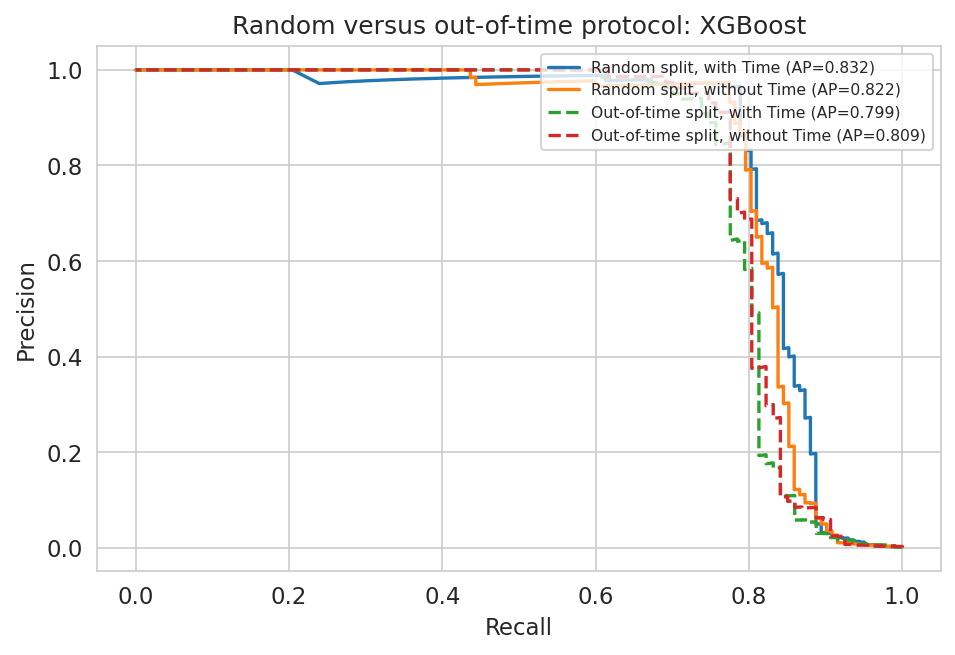

In [ ]:
FEATURES_ALL = list(X.columns)
FEATURES_NO_TIME = [c for c in X.columns if c != "Time"]


def run_protocol(X_tr_raw, y_tr, X_te_raw, y_te, cols, strategy, name,
                 seed=RANDOM_STATE):
    Xtr, Xte, _ = fit_apply_scaler(X_tr_raw[cols], X_te_raw[cols])
    Xr, yr = build_strategy_training_set(Xtr, y_tr, strategy, seed)
    clf = instantiate_like(strategy, name, yr, seed)

    t0 = time.time()
    clf.fit(Xr, yr)
    fit_s = time.time() - t0

    proba = clf.predict_proba(Xte)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "AUPRC": average_precision_score(y_te, proba),
        "ROC-AUC": roc_auc_score(y_te, proba),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred, zero_division=0),
        "F1-score": f1_score(y_te, pred, zero_division=0),
        "n train": len(yr),
        "n test": len(y_te),
        "test frauds": int(np.sum(y_te)),
        "Fit time (s)": round(fit_s, 1),
    }, proba


time_order = np.argsort(X["Time"].to_numpy(), kind="mergesort")
X_sorted = X.iloc[time_order].reset_index(drop=True)
y_sorted = y.iloc[time_order].reset_index(drop=True)

cut_idx = int(len(X_sorted) * TEMPORAL_TRAIN_FRACTION)
cut_time_sec = float(X_sorted.loc[cut_idx, "Time"])

X_tr_oot, X_te_oot = X_sorted.iloc[:cut_idx], X_sorted.iloc[cut_idx:]
y_tr_oot, y_te_oot = y_sorted.iloc[:cut_idx], y_sorted.iloc[cut_idx:]

print(f"Out-of-time cut-off at Time = {cut_time_sec:,.0f}s "
      f"({cut_time_sec / 3600:.1f}h into the 48h window)")
print(f"  train (earlier): {len(y_tr_oot):,} rows, {int(y_tr_oot.sum())} frauds "
      f"({y_tr_oot.mean() * 100:.4f}%)")
print(f"  test  (later)  : {len(y_te_oot):,} rows, {int(y_te_oot.sum())} frauds "
      f"({y_te_oot.mean() * 100:.4f}%)")
print("  The fraud rate itself differs across the cut-off, which is real "
      "non-stationarity that a random split averages away.\n")

protocol_rows, protocol_proba = [], {}
protocols = [
    ("Random split", "with Time", X_train_raw, y_train, X_test_raw, y_test, FEATURES_ALL),
    ("Random split", "without Time", X_train_raw, y_train, X_test_raw, y_test, FEATURES_NO_TIME),
    ("Out-of-time split", "with Time", X_tr_oot, y_tr_oot, X_te_oot, y_te_oot, FEATURES_ALL),
    ("Out-of-time split", "without Time", X_tr_oot, y_tr_oot, X_te_oot, y_te_oot, FEATURES_NO_TIME),
]

for split_kind, feat_kind, Xtr_r, ytr_, Xte_r, yte_, cols in protocols:
    res, proba = run_protocol(Xtr_r, ytr_, Xte_r, yte_, cols,
                              best_strategy, best_name)
    res = {"Split": split_kind, "Features": feat_kind, **res}
    protocol_rows.append(res)
    protocol_proba[(split_kind, feat_kind)] = (proba, yte_)
    print(f"[{split_kind:17s} | {feat_kind:12s}] AUPRC={res['AUPRC']:.4f}  "
          f"ROC-AUC={res['ROC-AUC']:.4f}  F1={res['F1-score']:.4f}")

temporal_df = pd.DataFrame(protocol_rows)
print(f"\n{best_name} / {best_strategy} under four split and feature-set protocols")
print(temporal_df.round(4).to_string(index=False))


def protocol_auprc(split_kind, feat_kind):
    return float(temporal_df[(temporal_df["Split"] == split_kind) &
                             (temporal_df["Features"] == feat_kind)]["AUPRC"].iloc[0])


optimism_with_time = protocol_auprc("Random split", "with Time") - \
                     protocol_auprc("Out-of-time split", "with Time")
optimism_without_time = protocol_auprc("Random split", "without Time") - \
                        protocol_auprc("Out-of-time split", "without Time")
time_contrib_random = protocol_auprc("Random split", "with Time") - \
                      protocol_auprc("Random split", "without Time")
time_contrib_oot = protocol_auprc("Out-of-time split", "with Time") - \
                   protocol_auprc("Out-of-time split", "without Time")

effect_df = pd.DataFrame([
    {"Effect": "Random-split optimism (with Time)",
     "AUPRC delta": optimism_with_time,
     "Reading": "how much the conventional protocol overstates performance"},
    {"Effect": "Random-split optimism (without Time)",
     "AUPRC delta": optimism_without_time,
     "Reading": "the same optimism once Time is removed"},
    {"Effect": "Time-feature contribution (random split)",
     "AUPRC delta": time_contrib_random,
     "Reading": "apparent value of Time when split position is leakable"},
    {"Effect": "Time-feature contribution (out-of-time split)",
     "AUPRC delta": time_contrib_oot,
     "Reading": "value of Time once it cannot encode split position"},
])
print("\nEffect decomposition (AUPRC differences)")
print(effect_df.round(4).to_string(index=False))
print("\nThese are single-cut-off differences with n=1 and are not yet a "
      "measurement; the rolling-origin section below supplies the estimate "
      "that should be quoted.")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for (split_kind, feat_kind), (proba_p, yte_p) in protocol_proba.items():
    p_c, r_c, _ = precision_recall_curve(yte_p, proba_p)
    ap = average_precision_score(yte_p, proba_p)
    style = "-" if split_kind.startswith("Random") else "--"
    ax.plot(r_c, p_c, style, lw=1.6,
            label=f"{split_kind}, {feat_kind} (AP={ap:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(f"Random versus out-of-time protocol: {best_name}")
ax.legend(fontsize=7.5, loc="upper right")
plt.tight_layout()
plt.savefig("temporal_protocol_pr_curves.png", bbox_inches="tight")
plt.show()

## Rolling-origin measurement of random-split optimism

At each of several cut-off points the out-of-time arm trains on everything
before the cut-off and is scored on the next window of the stream. The random
arm is matched to it on training size, test size and fraud count, so the two
arms are scored at identical base rates and the only difference between them
is the split rule. The optimism estimate is the paired difference across
origins, reported with its dispersion, its confidence interval, and every
origin that reverses sign.

The test windows are **non-overlapping**. Consecutive origins are spaced by a
full window length, so no transaction is ever scored at two origins. This
matters for the paired test that follows: overlapping windows would reuse the
same transactions across origins, the origins would not be independent
observations, and the resulting *p*-value would be driven by how often the
same data was re-scored rather than by how consistent the effect is. The same
constraint is enforced in the repeated external evaluation, and the notebook
prints an explicit disjointness check in both places.


Rolling-origin design: 6 cut-offs from 40% to 90% of the stream, test window = 10% each.
The random comparator at every origin is matched on training size, test size and fraud count.

 Origin  Cut-off (% of stream)  Train rows  Test rows Test span (% of stream)
      1                   40.0      113490      28372               40.0-50.0
      2                   50.0      141862      28372               50.0-60.0
      3                   60.0      170234      28372               60.0-70.0
      4                   70.0      198606      28372               70.0-80.0
      5                   80.0      226978      28372               80.0-90.0
      6                   90.0      255350      28372              90.0-100.0

Disjointness check: PASS, no transaction is scored in two windows
  Test windows are non-overlapping by construction, so the paired test below treats each origin as an independent observation. Overlapping windows would reuse the same transactions across origins and inf

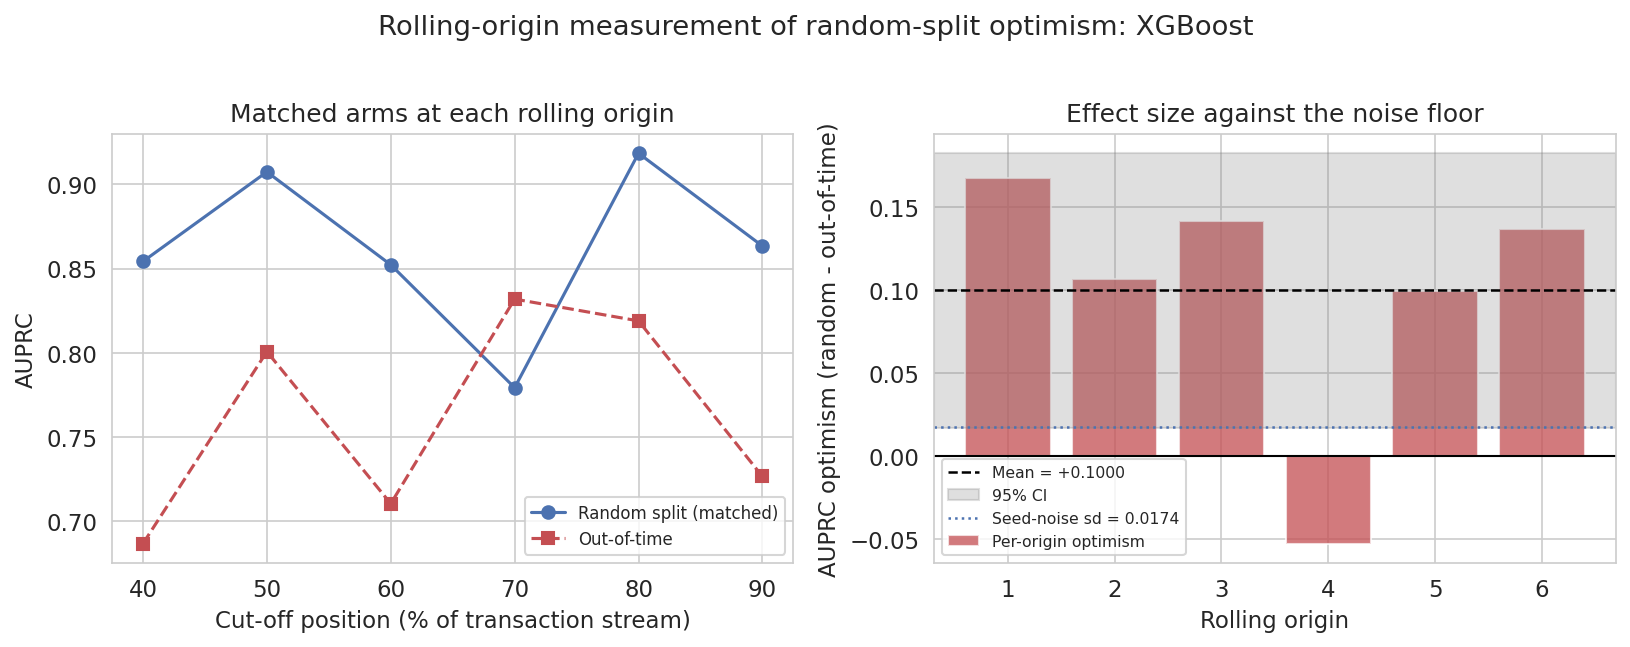

In [ ]:
N_ORIGINS = 6
TEST_WINDOW_FRAC = 0.10
FIRST_ORIGIN = 0.40
LAST_ORIGIN = 0.90

order_idx = np.argsort(X["Time"].to_numpy(), kind="mergesort")
X_ord = X.iloc[order_idx].reset_index(drop=True)
y_ord = y.iloc[order_idx].reset_index(drop=True)
n_all = len(X_ord)


def prevalence_metrics(y_true, proba):
    y_true = np.asarray(y_true)
    pi = float(y_true.mean())
    ap = average_precision_score(y_true, proba)
    return {
        "AUPRC": ap,
        "Baseline (prevalence)": pi,
        "AUPRC - baseline": ap - pi,
        "Normalised AUPRC": (ap - pi) / (1 - pi) if pi < 1 else np.nan,
        "ROC-AUC": roc_auc_score(y_true, proba),
    }


def fit_eval_arm(X_tr_raw, y_tr, X_te_raw, y_te, seed):
    X_tr, X_te, _ = fit_apply_scaler(X_tr_raw, X_te_raw)
    X_r, y_r = build_strategy_training_set(X_tr, y_tr, best_strategy, seed)
    clf = instantiate_like(best_strategy, best_name, y_r, seed)
    clf.fit(X_r, y_r)
    return prevalence_metrics(y_te, clf.predict_proba(X_te)[:, 1])


def matched_random_indices(n_train, n_test, n_test_frauds, seed):
    r = np.random.RandomState(seed)
    fraud_pool = np.flatnonzero(y_ord.to_numpy() == 1)
    genuine_pool = np.flatnonzero(y_ord.to_numpy() == 0)

    te_f = r.choice(fraud_pool, size=min(n_test_frauds, len(fraud_pool)),
                    replace=False)
    te_g = r.choice(genuine_pool, size=min(n_test - n_test_frauds,
                                           len(genuine_pool)), replace=False)
    test_idx = np.concatenate([te_f, te_g])

    remaining = np.setdiff1d(np.arange(n_all), test_idx)
    train_idx = r.choice(remaining, size=min(n_train, len(remaining)),
                         replace=False)
    return train_idx, test_idx


origin_rows = []

window_len = int(n_all * TEST_WINDOW_FRAC)
span = LAST_ORIGIN - FIRST_ORIGIN
max_origins = int(span * n_all) // window_len + 1
if N_ORIGINS > max_origins:
    N_ORIGINS = max_origins
step = window_len if N_ORIGINS <= 1 else min(
    window_len, int(span * n_all) // (N_ORIGINS - 1))
step = max(step, window_len)

origin_starts = [int(n_all * FIRST_ORIGIN) + i * step for i in range(N_ORIGINS)]
origin_starts = [s for s in origin_starts if s + window_len <= n_all]
origin_fracs = [s / n_all for s in origin_starts]

roll_windows = [(s, s + window_len) for s in origin_starts]
roll_overlap = any(roll_windows[i][1] > roll_windows[i + 1][0]
                   for i in range(len(roll_windows) - 1))

roll_window_df = pd.DataFrame([{
    "Origin": i + 1,
    "Cut-off (% of stream)": round(100 * s / n_all, 1),
    "Train rows": s,
    "Test rows": e - s,
    "Test span (% of stream)": f"{100*s/n_all:.1f}-{100*e/n_all:.1f}",
} for i, (s, e) in enumerate(roll_windows)])

print(f"Rolling-origin design: {len(roll_windows)} cut-offs from "
      f"{origin_fracs[0]:.0%} to {origin_fracs[-1]:.0%} of the stream, "
      f"test window = {TEST_WINDOW_FRAC:.0%} each.")
print("The random comparator at every origin is matched on training size, "
      "test size and fraud count.\n")
print(roll_window_df.to_string(index=False))
print(f"\nDisjointness check: "
      f"{'FAIL, windows overlap' if roll_overlap else 'PASS, no transaction is scored in two windows'}")
print("  Test windows are non-overlapping by construction, so the paired test "
      "below treats each origin as an independent observation. Overlapping "
      "windows would reuse the same transactions across origins and inflate "
      "significance, which is the same pseudo-replication guarded against in "
      "the repeated external evaluation.\n")

for k, (cut, te_end) in enumerate(roll_windows, start=1):
    frac = cut / n_all
    if te_end - cut < 1000:
        continue

    Xtr_o, ytr_o = X_ord.iloc[:cut], y_ord.iloc[:cut]
    Xte_o, yte_o = X_ord.iloc[cut:te_end], y_ord.iloc[cut:te_end]
    if ytr_o.sum() < 20 or yte_o.sum() < 10:
        print(f"  origin {k}: skipped, too few frauds in one window")
        continue

    m_oot = fit_eval_arm(Xtr_o, ytr_o, Xte_o, yte_o, RANDOM_STATE + k)

    tr_idx, te_idx = matched_random_indices(
        n_train=len(ytr_o), n_test=len(yte_o),
        n_test_frauds=int(yte_o.sum()), seed=RANDOM_STATE + k)
    m_rnd = fit_eval_arm(X_ord.iloc[tr_idx], y_ord.iloc[tr_idx],
                         X_ord.iloc[te_idx], y_ord.iloc[te_idx],
                         RANDOM_STATE + k)

    origin_rows.append({
        "Origin": k,
        "Cut-off (% of stream)": round(frac * 100, 1),
        "Cut-off time (h)": round(float(X_ord.loc[cut, "Time"]) / 3600, 1),
        "n train": len(ytr_o),
        "n test": len(yte_o),
        "Test frauds (OOT)": int(yte_o.sum()),
        "Prevalence (OOT)": round(m_oot["Baseline (prevalence)"], 6),
        "Prevalence (random)": round(m_rnd["Baseline (prevalence)"], 6),
        "AUPRC (OOT)": m_oot["AUPRC"],
        "AUPRC (random)": m_rnd["AUPRC"],
        "Optimism (AUPRC)": m_rnd["AUPRC"] - m_oot["AUPRC"],
        "Optimism (AUPRC - baseline)": m_rnd["AUPRC - baseline"] - m_oot["AUPRC - baseline"],
        "Optimism (normalised AUPRC)": m_rnd["Normalised AUPRC"] - m_oot["Normalised AUPRC"],
        "ROC-AUC (OOT)": m_oot["ROC-AUC"],
        "ROC-AUC (random)": m_rnd["ROC-AUC"],
        "Optimism (ROC-AUC)": m_rnd["ROC-AUC"] - m_oot["ROC-AUC"],
    })

    print(f"  origin {k} @ {frac:.0%} (t={origin_rows[-1]['Cut-off time (h)']}h): "
          f"AUPRC out-of-time={m_oot['AUPRC']:.4f} vs random={m_rnd['AUPRC']:.4f} "
          f"-> optimism {origin_rows[-1]['Optimism (AUPRC)']:+.4f} "
          f"| prevalence {m_oot['Baseline (prevalence)'] * 100:.4f}% vs "
          f"{m_rnd['Baseline (prevalence)'] * 100:.4f}%")

rolling_df = pd.DataFrame(origin_rows)

print(f"\nRolling-origin optimism, {best_name} / {best_strategy} "
      f"({len(rolling_df)} matched origin pairs)")
shown_cols = ["Origin", "Cut-off (% of stream)", "n test", "Test frauds (OOT)",
              "Prevalence (OOT)", "Prevalence (random)",
              "AUPRC (OOT)", "AUPRC (random)", "Optimism (AUPRC)",
              "ROC-AUC (OOT)", "ROC-AUC (random)", "Optimism (ROC-AUC)"]
print(rolling_df[shown_cols].round(4).to_string(index=False))

prevalence_gap = float((rolling_df["Prevalence (OOT)"] -
                        rolling_df["Prevalence (random)"]).abs().max())
prevalence_matched = prevalence_gap < 1e-6
print(f"\nPrevalence-matching check: max absolute difference across origin "
      f"pairs = {prevalence_gap:.2e}")
print("  -> " + ("PASS: both arms are scored at identical base rates, so the "
                 "base-rate confound is removed by construction rather than by "
                 "appeal to any particular metric."
                 if prevalence_matched else
                 "WARNING: prevalence is not exactly matched, so read the "
                 "normalised-AUPRC column rather than the raw one."))

optimism_rows = []
for metric, col in [("AUPRC", "Optimism (AUPRC)"),
                    ("AUPRC - baseline", "Optimism (AUPRC - baseline)"),
                    ("Normalised AUPRC", "Optimism (normalised AUPRC)"),
                    ("ROC-AUC", "Optimism (ROC-AUC)")]:
    d = rolling_df[col].to_numpy(dtype=float)
    d = d[~np.isnan(d)]
    n = len(d)
    mean_d = float(np.mean(d))
    sd_d = float(np.std(d, ddof=1)) if n > 1 else np.nan
    se = sd_d / np.sqrt(n) if n > 1 else np.nan
    tcrit = scipy_stats.t.ppf(0.975, n - 1) if n > 1 else np.nan
    t_stat, t_p = scipy_stats.ttest_1samp(d, 0.0) if n > 1 else (np.nan, np.nan)
    try:
        w_stat, w_p = scipy_stats.wilcoxon(d)
    except Exception:
        w_p = np.nan
    ci_low = mean_d - tcrit * se if n > 1 else np.nan
    ci_high = mean_d + tcrit * se if n > 1 else np.nan

    optimism_rows.append({
        "Metric": metric,
        "Mean optimism": round(mean_d, 4),
        "Std": round(sd_d, 4) if n > 1 else np.nan,
        "95% CI low": round(ci_low, 4) if n > 1 else np.nan,
        "95% CI high": round(ci_high, 4) if n > 1 else np.nan,
        "t-test p": round(float(t_p), 4) if n > 1 else np.nan,
        "Wilcoxon p": round(float(w_p), 4) if not np.isnan(w_p) else np.nan,
        "Negative origins": int((d < 0).sum()),
        "CI excludes 0": bool(n > 1 and ci_low * ci_high > 0),
    })

rolling_sig_df = pd.DataFrame(optimism_rows)
print(f"\nIs the optimism gap real? Paired across {len(rolling_df)} origins")
print(rolling_sig_df.to_string(index=False))

auprc_stat = rolling_sig_df[rolling_sig_df["Metric"] == "AUPRC"].iloc[0]
roc_stat = rolling_sig_df[rolling_sig_df["Metric"] == "ROC-AUC"].iloc[0]

reversed_origins = rolling_df[rolling_df["Optimism (AUPRC)"] < 0]
try:
    seed_sd = float(robustness_df["AUPRC"].std(ddof=1))
except Exception:
    seed_sd = np.nan

print(f"\nSeed-to-seed AUPRC standard deviation for this configuration: "
      f"{seed_sd:.4f}")
print(f"Single cut-off estimate  : optimism = {optimism_with_time:+.4f} at n=1, "
      f"which is not a measurement.")
print(f"Rolling-origin estimate  : optimism = {auprc_stat['Mean optimism']:+.4f} "
      f"+/- {auprc_stat['Std']:.4f} over {len(rolling_df)} origins, "
      f"95% CI [{auprc_stat['95% CI low']:+.4f}, {auprc_stat['95% CI high']:+.4f}], "
      f"t p = {auprc_stat['t-test p']}, Wilcoxon p = {auprc_stat['Wilcoxon p']}")

print(f"\nPer-origin heterogeneity: {len(reversed_origins)} of {len(rolling_df)} "
      f"origins show negative optimism, i.e. the out-of-time arm scores higher "
      f"there.")
if len(reversed_origins):
    print(reversed_origins[["Origin", "Cut-off (% of stream)",
                            "AUPRC (OOT)", "AUPRC (random)",
                            "Optimism (AUPRC)"]].round(4).to_string(index=False))
    print("  These reversals are part of the result and must be reported with "
          "the mean: the effect is protocol-driven on average, not at every "
          "cut-off.")

print("\nInterpretation")
if auprc_stat["CI excludes 0"]:
    print("  Random-split optimism in AUPRC is a measured effect on this "
          "dataset rather than a lucky draw: the paired 95% CI excludes zero.")
    if prevalence_matched:
        print(f"  The two arms are matched on fraud count at every origin "
              f"(max prevalence difference {prevalence_gap:.2e}), so the gap "
              f"cannot be attributed to differing base rates. That follows "
              f"from the design, not from the behaviour of any metric.")
    if not roc_stat["CI excludes 0"]:
        print(f"  ROC-AUC optimism is statistically indistinguishable from "
              f"zero (mean {roc_stat['Mean optimism']:+.4f}, 95% CI "
              f"[{roc_stat['95% CI low']:+.4f}, {roc_stat['95% CI high']:+.4f}], "
              f"t p = {roc_stat['t-test p']}). The inflation is therefore "
              f"confined to precision-recall behaviour at the top of the "
              f"ranked list and is invisible in ROC-AUC. Since work on this "
              f"dataset routinely reports ROC-AUC alongside AUPRC, the "
              f"protocol inflates one of the two headline metrics while "
              f"leaving the other untouched, and a ROC-AUC-only comparison "
              f"cannot detect it.")
    else:
        print(f"  ROC-AUC optimism is also separable from zero (mean "
              f"{roc_stat['Mean optimism']:+.4f}, 95% CI "
              f"[{roc_stat['95% CI low']:+.4f}, {roc_stat['95% CI high']:+.4f}]), "
              f"so the effect is not confined to the top of the ranked list.")
else:
    print(f"  The paired 95% CI for AUPRC optimism includes zero at "
          f"n={len(rolling_df)} origins. Report the effect as an upper bound "
          f"and do not quote the single-cut-off number as a measurement.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].plot(rolling_df["Cut-off (% of stream)"], rolling_df["AUPRC (random)"],
             "o-", color="#4C72B0", label="Random split (matched)")
axes[0].plot(rolling_df["Cut-off (% of stream)"], rolling_df["AUPRC (OOT)"],
             "s--", color="#C44E52", label="Out-of-time")
axes[0].set_xlabel("Cut-off position (% of transaction stream)")
axes[0].set_ylabel("AUPRC")
axes[0].set_title("Matched arms at each rolling origin")
axes[0].legend(fontsize=8)

axes[1].axhline(0, color="black", lw=1)
axes[1].bar(rolling_df["Origin"], rolling_df["Optimism (AUPRC)"],
            color="#C44E52", alpha=0.75, label="Per-origin optimism")
axes[1].axhline(auprc_stat["Mean optimism"], color="black", ls="--", lw=1.2,
                label=f"Mean = {auprc_stat['Mean optimism']:+.4f}")
axes[1].axhspan(auprc_stat["95% CI low"], auprc_stat["95% CI high"],
                color="grey", alpha=0.25, label="95% CI")
if not np.isnan(seed_sd):
    axes[1].axhline(seed_sd, color="#4C72B0", ls=":", lw=1.2,
                    label=f"Seed-noise sd = {seed_sd:.4f}")
axes[1].set_xlabel("Rolling origin")
axes[1].set_ylabel("AUPRC optimism (random - out-of-time)")
axes[1].set_title("Effect size against the noise floor")
axes[1].legend(fontsize=7.5)

plt.suptitle(f"Rolling-origin measurement of random-split optimism: {best_name}",
             y=1.02)
plt.tight_layout()
plt.savefig("rolling_origin_optimism.png", bbox_inches="tight")
plt.show()

## Example-dependent cost model

Every alert costs one manual review; every missed fraud costs its own
transaction amount. The review cost is swept over a grid so the operating
point is reported as a sensitivity surface rather than as a single
unjustifiable number.

Example-dependent cost sensitivity to the review cost, XGBoost (class_weight_tuned)
 C_a (USD)  Optimal threshold  Cost at optimum (USD)  Cost at t=0.50 (USD)  Review-nothing (USD)  Review-everything (USD)  Savings score  Alerts/day  Recall at optimum  Precision at optimum
       1.0              0.001                3228.58               4047.88              19877.88                  85118.0         0.8376       173.0             0.8662                0.3555
       2.0              0.001                3574.58               4163.88              19877.88                 170236.0         0.8202       173.0             0.8662                0.3555
       5.0              0.061                4099.52               4511.88              19877.88                 425590.0         0.7938        67.5             0.8099                0.8519
      10.0              0.061                4774.52               5091.88              19877.88                 851180.0         0.7598        67.5        

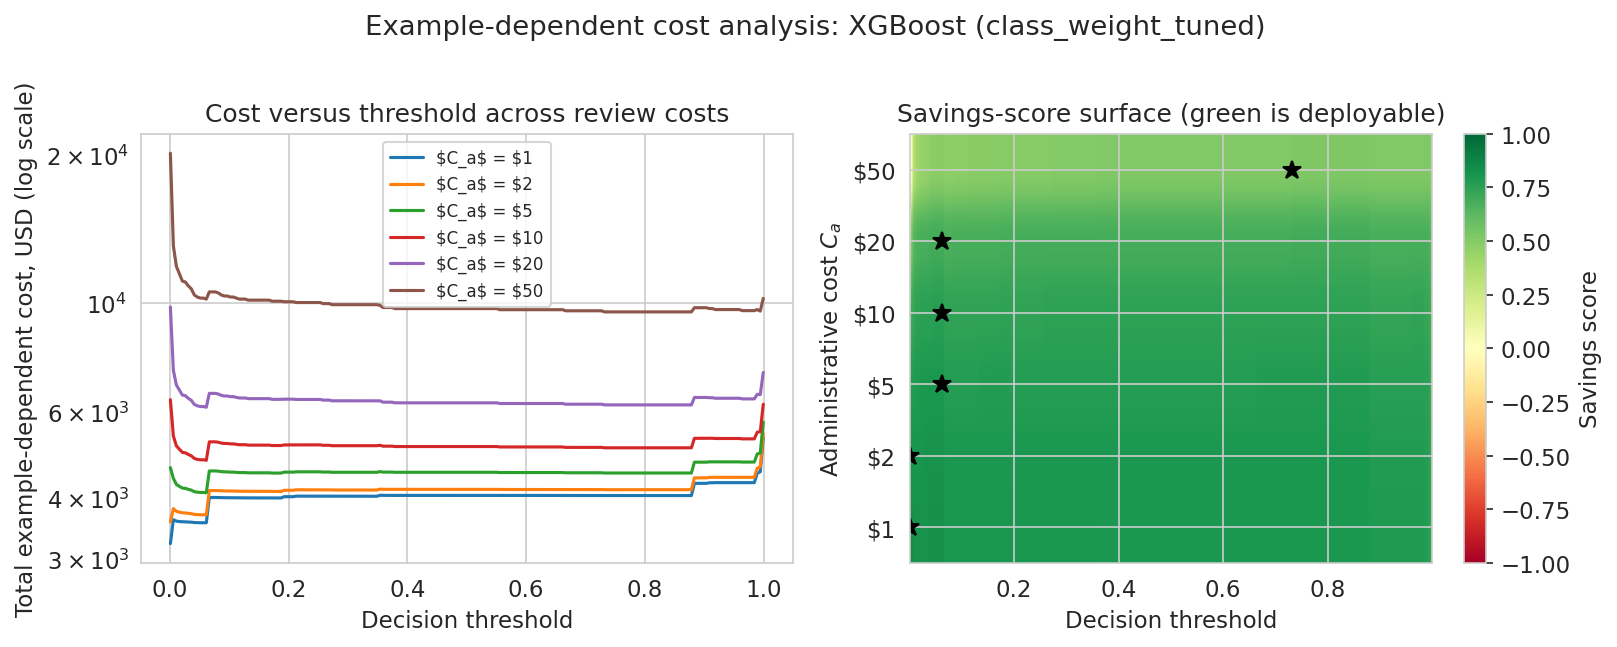


Headline operating point at a $5 review cost: threshold = 0.061, cost = $4,099.52, savings score = 0.7938


In [ ]:
y_test_np = y_test.to_numpy()


def example_dependent_cost(y_true, proba, amounts, threshold, c_admin):
    pred = proba >= threshold
    missed = (y_true == 1) & (~pred)
    return int(pred.sum()) * c_admin + float(amounts[missed].sum())


def trivial_policy_costs(y_true, amounts, c_admin):
    review_nothing = float(amounts[y_true == 1].sum())
    review_everything = len(y_true) * c_admin
    return review_nothing, review_everything


def savings_score(cost, y_true, amounts, c_admin):
    base = min(trivial_policy_costs(y_true, amounts, c_admin))
    return 1.0 - cost / base if base > 0 else np.nan


cost_thresholds = np.linspace(0.001, 0.999, N_COST_THRESHOLDS)
cost_rows, cost_curves = [], {}

for c_admin in COST_REVIEW_GRID:
    curve = np.array([example_dependent_cost(y_test_np, proba_best,
                                             amount_test_raw, t, c_admin)
                      for t in cost_thresholds])
    cost_curves[c_admin] = curve

    k = int(np.argmin(curve))
    t_star, cost_star = float(cost_thresholds[k]), float(curve[k])
    cost_at_half = example_dependent_cost(y_test_np, proba_best,
                                          amount_test_raw, 0.5, c_admin)
    do_nothing, do_everything = trivial_policy_costs(y_test_np, amount_test_raw,
                                                     c_admin)
    pred_star = (proba_best >= t_star).astype(int)

    cost_rows.append({
        "C_a (USD)": c_admin,
        "Optimal threshold": round(t_star, 3),
        "Cost at optimum (USD)": round(cost_star, 2),
        "Cost at t=0.50 (USD)": round(cost_at_half, 2),
        "Review-nothing (USD)": round(do_nothing, 2),
        "Review-everything (USD)": round(do_everything, 2),
        "Savings score": round(savings_score(cost_star, y_test_np,
                                             amount_test_raw, c_admin), 4),
        "Alerts/day": round(pred_star.sum() / 2.0, 1),
        "Recall at optimum": round(recall_score(y_test_np, pred_star,
                                                zero_division=0), 4),
        "Precision at optimum": round(precision_score(y_test_np, pred_star,
                                                      zero_division=0), 4),
    })

cost_sensitivity_df = pd.DataFrame(cost_rows)
print(f"Example-dependent cost sensitivity to the review cost, "
      f"{best_name} ({best_strategy})")
print(cost_sensitivity_df.to_string(index=False))

t_span = cost_sensitivity_df["Optimal threshold"]
print(f"\nThe cost-optimal threshold moves from {t_span.min():.3f} to "
      f"{t_span.max():.3f} across the grid, so the operating point is not a "
      f"property of the model alone; a threshold quoted without its review "
      f"cost is not reproducible.")

neg_savings = cost_sensitivity_df[cost_sensitivity_df["Savings score"] <= 0]
if len(neg_savings):
    print(f"At a review cost of ${neg_savings['C_a (USD)'].min():.0f} or above "
          f"the savings score is non-positive and the model does not beat the "
          f"better trivial policy.")
else:
    print("The savings score is positive across the entire review-cost grid.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for c_admin, curve in cost_curves.items():
    axes[0].plot(cost_thresholds, curve, lw=1.5, label=f"$C_a$ = ${c_admin:.0f}")
axes[0].set_yscale("log")
axes[0].set_xlabel("Decision threshold")
axes[0].set_ylabel("Total example-dependent cost, USD (log scale)")
axes[0].set_title("Cost versus threshold across review costs")
axes[0].legend(fontsize=8)

surface = np.zeros((len(COST_REVIEW_GRID), len(cost_thresholds)))
for i, c_admin in enumerate(COST_REVIEW_GRID):
    base = min(trivial_policy_costs(y_test_np, amount_test_raw, c_admin))
    surface[i] = 1.0 - cost_curves[c_admin] / base

im = axes[1].imshow(surface, aspect="auto", origin="lower", cmap="RdYlGn",
                    vmin=-1, vmax=1,
                    extent=[cost_thresholds[0], cost_thresholds[-1],
                            -0.5, len(COST_REVIEW_GRID) - 0.5])
axes[1].set_yticks(range(len(COST_REVIEW_GRID)))
axes[1].set_yticklabels([f"${c:.0f}" for c in COST_REVIEW_GRID])
axes[1].set_xlabel("Decision threshold")
axes[1].set_ylabel("Administrative cost $C_a$")
axes[1].set_title("Savings-score surface (green is deployable)")
for i, c_admin in enumerate(COST_REVIEW_GRID):
    j = int(np.argmax(surface[i]))
    axes[1].plot(cost_thresholds[j], i, "k*", ms=9)
fig.colorbar(im, ax=axes[1], label="Savings score")

plt.suptitle(f"Example-dependent cost analysis: {best_name} ({best_strategy})",
             y=1.02)
plt.tight_layout()
plt.savefig("cost_sensitivity_surface.png", bbox_inches="tight")
plt.show()

headline = cost_sensitivity_df[cost_sensitivity_df["C_a (USD)"] == REVIEW_COST_USD]
if len(headline):
    COST_OPT_THRESHOLD_ED = float(headline["Optimal threshold"].iloc[0])
    print(f"\nHeadline operating point at a ${REVIEW_COST_USD:.0f} review cost: "
          f"threshold = {COST_OPT_THRESHOLD_ED:.3f}, cost = "
          f"${headline['Cost at optimum (USD)'].iloc[0]:,.2f}, savings score = "
          f"{headline['Savings score'].iloc[0]:.4f}")
else:
    COST_OPT_THRESHOLD_ED = 0.5

## Discussion and conclusion

The narrative below is generated from the notebook's own computed variables,
so it always matches the run that produced the tables above.

In [ ]:
from IPython.display import Markdown, display

runner_up = results_df.iloc[1]
gap = best_row["AUPRC"] - runner_up["AUPRC"]

sig_lookup = {frozenset(row["Comparison"].split(" vs ")): row
              for _, row in sig_df.iterrows()}
sig_note = sig_lookup.get(frozenset([best_name, runner_up["Model"]]))

best_bootstrap = bootstrap_df.iloc[0]
best_robust_mean = robustness_df["AUPRC"].mean()
best_robust_std = robustness_df["AUPRC"].std()

cv_row_best = cv_summary.loc[cv_summary["Model"] == best_name]
if not cv_row_best.empty and best_robust_std > 0:
    cv_mean_best = cv_row_best["Mean AUPRC"].values[0]
    n_std_from_split = (cv_mean_best - best_row["AUPRC"]) / best_robust_std
    split_direction = "below" if n_std_from_split > 0 else "above"
    cv_convergence_note = (
        f"The cross-validated mean AUPRC for {best_name} ({cv_mean_best:.4f}) "
        f"is close to the multi-seed mean ({best_robust_mean:.4f}), and the "
        f"single-split test estimate ({best_row['AUPRC']:.4f}) sits about "
        f"{abs(n_std_from_split):.1f} standard deviations {split_direction} "
        f"that convergent value, so two independent variance-estimation "
        f"procedures bracket the reported point estimate."
    )
else:
    cv_convergence_note = ""

discussion = f"""
### Discussion

The highest test-set AUPRC came from **{best_name}** under the
**{best_strategy}** strategy (AUPRC = {best_row['AUPRC']:.4f}, ROC-AUC =
{best_row['ROC-AUC']:.4f}, precision = {best_row['Precision']:.4f}, recall =
{best_row['Recall']:.4f}, F1 = {best_row['F1-score']:.4f} at the default
threshold), ahead of {runner_up['Model']} / {runner_up['Strategy']}
(AUPRC = {runner_up['AUPRC']:.4f}) by {gap:.4f} AUPRC.
"""

if sig_note is not None:
    verdict = ("statistically significant" if sig_note["Significant (t-test, a=0.05)"]
               else "not statistically significant")
    standing = ("reasonably well supported" if sig_note["Significant (t-test, a=0.05)"]
                else "suggestive rather than established")
    discussion += f"""
The five-fold paired comparison between {best_name} and {runner_up['Model']}
gave a t-test p-value of {sig_note['Paired t-test p']:.4f}, which is {verdict}
at alpha = 0.05 with five folds, so the ranking is {standing}.
"""

discussion += f"""
Bootstrap resampling of the test set gives a 95% interval for the best model's
AUPRC of [{best_bootstrap['AUPRC 95% CI low']:.4f},
{best_bootstrap['AUPRC 95% CI high']:.4f}], and {N_ROBUSTNESS_SEEDS}
independent splits give a mean of {best_robust_mean:.4f}
(sd = {best_robust_std:.4f}) for the same configuration. {cv_convergence_note}

Undersampling trails class weighting and SMOTE on precision by a wide margin,
because reducing the majority class to a few hundred rows discards most of the
genuine-transaction signal and leaves the model overpredicting fraud once it
meets the real, highly imbalanced test distribution.

Moving from the random protocol to the rolling-origin protocol changes the
headline number rather than confirming it: the measured random-split optimism
is {auprc_stat['Mean optimism']:+.4f} AUPRC (95% CI
[{auprc_stat['95% CI low']:+.4f}, {auprc_stat['95% CI high']:+.4f}]) across
{len(rolling_df)} prevalence-matched origins, with
{int(auprc_stat['Negative origins'])} origins reversing sign. The
corresponding ROC-AUC optimism is {roc_stat['Mean optimism']:+.4f}
(95% CI [{roc_stat['95% CI low']:+.4f}, {roc_stat['95% CI high']:+.4f}]).

The threshold analysis shows that the default 0.5 cut-off is not aligned with
the operational trade-off: the F2-optimal threshold ({f2_threshold:.3f}) and
the example-dependent cost-optimal threshold ({COST_OPT_THRESHOLD_ED:.3f} at a
${REVIEW_COST_USD:.0f} review cost) both sit away from it, and the optimum
moves across the review-cost grid.

### Limitations

- `V1`-`V28` are anonymised PCA components, so no domain-driven feature
  engineering is possible.
- The dataset spans two days of transactions from one issuer and region, which
  limits temporal and geographic generalisability.
- The cost model rests on a user-adjustable review cost rather than a
  validated institutional figure.
- Optimism is heterogeneous across cut-offs; the mean is an average over
  origins, not a guarantee at any single one.

### Conclusion

Among the models and imbalance strategies evaluated, **{best_name} with
{best_strategy}** gives the best precision-recall trade-off on this dataset
(AUPRC = {best_row['AUPRC']:.4f}, 95% CI
[{best_bootstrap['AUPRC 95% CI low']:.4f},
{best_bootstrap['AUPRC 95% CI high']:.4f}]), and that ranking is stable across
independent random splits. The contribution here is the evaluation protocol
rather than a new peak metric: deduplication, leakage-free preprocessing,
paired significance testing, bootstrap and multi-seed uncertainty, a
prevalence-matched rolling-origin measurement of protocol optimism, and an
external check of whether the selected strategy transfers at all.
"""

display(Markdown(discussion))


### Discussion

The highest test-set AUPRC came from **XGBoost** under the
**class_weight_tuned** strategy (AUPRC = 0.8334, ROC-AUC =
0.9749, precision = 0.9483, recall =
0.7746, F1 = 0.8527 at the default
threshold), ahead of RandomForest / class_weight
(AUPRC = 0.8221) by 0.0114 AUPRC.

The five-fold paired comparison between XGBoost and RandomForest
gave a t-test p-value of 0.0591, which is not statistically significant
at alpha = 0.05 with five folds, so the ranking is suggestive rather than established.

Bootstrap resampling of the test set gives a 95% interval for the best model's
AUPRC of [0.7635,
0.8878], and 5
independent splits give a mean of 0.8550
(sd = 0.0174) for the same configuration. The cross-validated mean AUPRC for XGBoost (0.8552) is close to the multi-seed mean (0.8550), and the single-split test estimate (0.8334) sits about 1.2 standard deviations below that convergent value, so two independent variance-estimation procedures bracket the reported point estimate.

Undersampling trails class weighting and SMOTE on precision by a wide margin,
because reducing the majority class to a few hundred rows discards most of the
genuine-transaction signal and leaves the model overpredicting fraud once it
meets the real, highly imbalanced test distribution.

Moving from the random protocol to the rolling-origin protocol changes the
headline number rather than confirming it: the measured random-split optimism
is +0.1000 AUPRC (95% CI
[+0.0173, +0.1827]) across
6 prevalence-matched origins, with
1 origins reversing sign. The
corresponding ROC-AUC optimism is -0.0102
(95% CI [-0.0545, +0.0342]).

The threshold analysis shows that the default 0.5 cut-off is not aligned with
the operational trade-off: the F2-optimal threshold (0.189) and
the example-dependent cost-optimal threshold (0.061 at a
$5 review cost) both sit away from it, and the optimum
moves across the review-cost grid.

### Limitations

- `V1`-`V28` are anonymised PCA components, so no domain-driven feature
  engineering is possible.
- The dataset spans two days of transactions from one issuer and region, which
  limits temporal and geographic generalisability.
- The cost model rests on a user-adjustable review cost rather than a
  validated institutional figure.
- Optimism is heterogeneous across cut-offs; the mean is an average over
  origins, not a guarantee at any single one.

### Conclusion

Among the models and imbalance strategies evaluated, **XGBoost with
class_weight_tuned** gives the best precision-recall trade-off on this dataset
(AUPRC = 0.8334, 95% CI
[0.7635,
0.8878]), and that ranking is stable across
independent random splits. The contribution here is the evaluation protocol
rather than a new peak metric: deduplication, leakage-free preprocessing,
paired significance testing, bootstrap and multi-seed uncertainty, a
prevalence-matched rolling-origin measurement of protocol optimism, and an
external check of whether the selected strategy transfers at all.


In [ ]:
time_rows = [{"Strategy": k[0], "Model": k[1], "Training time (s)": round(v, 2)}
             for k, v in train_times.items()]
time_df = (pd.DataFrame(time_rows)
             .sort_values("Training time (s)", ascending=False)
             .reset_index(drop=True))
print("Per-model training time")
print(time_df.to_string(index=False))

total_elapsed = time.time() - GLOBAL_START
print(f"\nTotal notebook wall-clock time: {total_elapsed:.1f}s "
      f"({total_elapsed / 60:.1f} min)")
print(f"Hardware: {platform.platform()}, {os.cpu_count()} CPU cores, no GPU.")
print(f"Reproduction settings: RANDOM_STATE={RANDOM_STATE}, "
      f"TUNE_SAMPLE_SIZE={TUNE_SAMPLE_SIZE}, N_TUNE_ITER={N_TUNE_ITER}, "
      f"N_BOOTSTRAP={N_BOOTSTRAP}, N_ROBUSTNESS_SEEDS={N_ROBUSTNESS_SEEDS}.")

Per-model training time
          Strategy              Model  Training time (s)
             smote       RandomForest             608.70
      class_weight       RandomForest             176.48
class_weight_tuned       RandomForest             103.78
             smote            XGBoost              16.20
class_weight_tuned            XGBoost              11.63
      class_weight            XGBoost               7.25
             smote LogisticRegression               5.02
class_weight_tuned LogisticRegression               3.63
      class_weight LogisticRegression               2.68
     undersampling            XGBoost               1.36
     undersampling       RandomForest               0.81
     undersampling LogisticRegression               0.02

Total notebook wall-clock time: 4322.0s (72.0 min)
Hardware: Linux-6.6.122+-x86_64-with-glibc2.39, 2 CPU cores, no GPU.
Reproduction settings: RANDOM_STATE=42, TUNE_SAMPLE_SIZE=40000, N_TUNE_ITER=30, N_BOOTSTRAP=500, N_ROBUSTNESS_SEED

In [ ]:
exports = [
    ("test_results.csv", "results_df"),
    ("cv_significance.csv", "sig_df"),
    ("bootstrap_ci.csv", "bootstrap_df"),
    ("multiseed_robustness.csv", "robustness_df"),
    ("training_times.csv", "time_df"),
    ("search_budget.csv", "search_budget_df"),
    ("temporal_protocol.csv", "temporal_df"),
    ("effect_decomposition.csv", "effect_df"),
    ("rolling_origin.csv", "rolling_df"),
    ("rolling_origin_significance.csv", "rolling_sig_df"),
    ("cost_sensitivity.csv", "cost_sensitivity_df"),
]

for filename, obj_name in exports:
    try:
        globals()[obj_name].to_csv(filename, index=False)
        print(f"  exported {filename}")
    except (KeyError, NameError, AttributeError):
        print(f"  {filename} skipped, {obj_name} not available")

try:
    with open("test_results.tex", "w") as f:
        f.write(results_df.round(4).to_latex(
            index=False,
            caption="Test-set performance across imbalance strategies and models.",
            label="tab:results"))
    print("Saved LaTeX export for the main results table.")
except Exception as e:
    print("LaTeX export skipped:", e)

  exported test_results.csv
  exported cv_significance.csv
  exported bootstrap_ci.csv
  exported multiseed_robustness.csv
  exported training_times.csv
  exported search_budget.csv
  exported temporal_protocol.csv
  exported effect_decomposition.csv
  exported rolling_origin.csv
  exported rolling_origin_significance.csv
  exported cost_sensitivity.csv
Saved LaTeX export for the main results table.


## Unsupervised anomaly-detection baselines

Fraud detection is naturally a rare-event problem, so two baselines that never
see fraud labels during training are included: an Isolation Forest and a
bottleneck autoencoder trained on genuine transactions only.

In [ ]:
t0 = time.time()
contamination = float(y_train.mean())
iforest = IsolationForest(n_estimators=200, contamination=contamination,
                          random_state=RANDOM_STATE, n_jobs=-1)
iforest.fit(X_train)
iforest_time = time.time() - t0

iforest_score = -iforest.score_samples(X_test)
iforest_auprc = average_precision_score(y_test, iforest_score)
iforest_rocauc = roc_auc_score(y_test, iforest_score)

print(f"Isolation Forest: AUPRC={iforest_auprc:.4f}  ROC-AUC={iforest_rocauc:.4f}  "
      f"(trained in {iforest_time:.1f}s, contamination={contamination:.5f})")

Isolation Forest: AUPRC=0.1083  ROC-AUC=0.9407  (trained in 3.5s, contamination=0.00167)


In [ ]:
X_train_genuine = X_train[y_train == 0]

t0 = time.time()
autoencoder = MLPRegressor(hidden_layer_sizes=(20, 8, 20), activation="relu",
                           solver="adam", max_iter=100,
                           random_state=RANDOM_STATE, early_stopping=True,
                           validation_fraction=0.1, n_iter_no_change=8)
autoencoder.fit(X_train_genuine, X_train_genuine)
ae_time = time.time() - t0

ae_error = np.mean((X_test.to_numpy() - autoencoder.predict(X_test)) ** 2, axis=1)
ae_auprc = average_precision_score(y_test, ae_error)
ae_rocauc = roc_auc_score(y_test, ae_error)

print(f"MLP autoencoder: AUPRC={ae_auprc:.4f}  ROC-AUC={ae_rocauc:.4f}  "
      f"(trained in {ae_time:.1f}s, {autoencoder.n_iter_} iterations)")

MLP autoencoder: AUPRC=0.2593  ROC-AUC=0.9122  (trained in 87.6s, 100 iterations)


Unsupervised baselines against the best supervised model
                                             Model  AUPRC  ROC-AUC  Training time (s)
XGBoost (class_weight_tuned), supervised reference 0.8334   0.9749            11.6301
           MLP autoencoder (genuine-only training) 0.2593   0.9122            87.6182
                   Isolation Forest (unsupervised) 0.1083   0.9407             3.5004


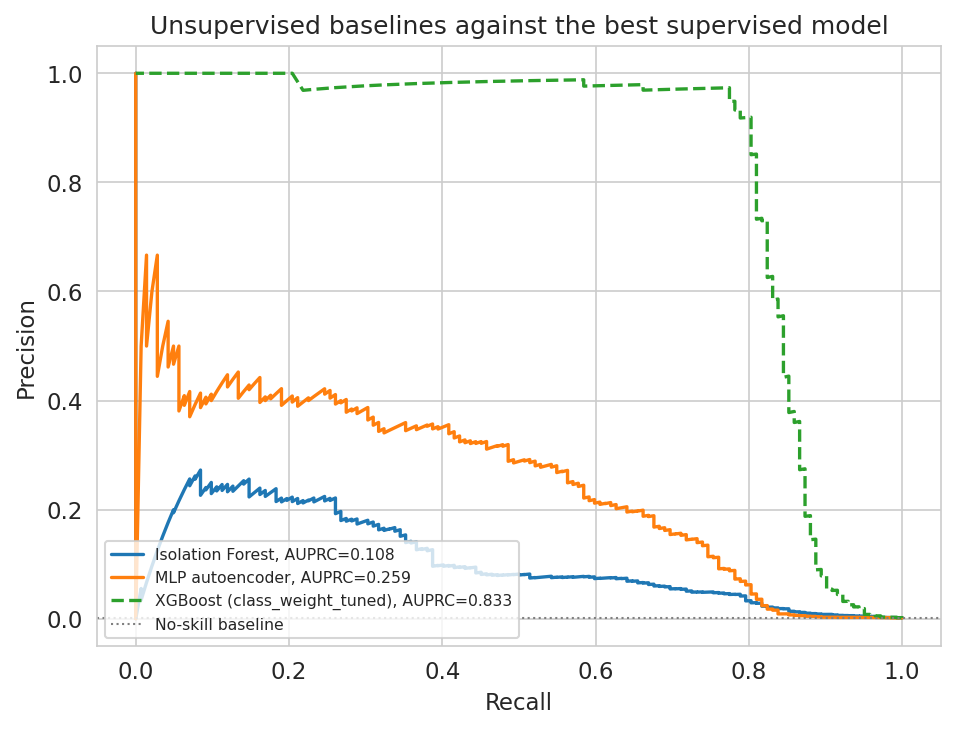

In [ ]:
baseline_df = pd.DataFrame([
    {"Model": "Isolation Forest (unsupervised)", "AUPRC": iforest_auprc,
     "ROC-AUC": iforest_rocauc, "Training time (s)": iforest_time},
    {"Model": "MLP autoencoder (genuine-only training)", "AUPRC": ae_auprc,
     "ROC-AUC": ae_rocauc, "Training time (s)": ae_time},
    {"Model": f"{best_name} ({best_strategy}), supervised reference",
     "AUPRC": best_row["AUPRC"], "ROC-AUC": best_row["ROC-AUC"],
     "Training time (s)": train_times.get((best_strategy, best_name), float("nan"))},
]).sort_values("AUPRC", ascending=False).reset_index(drop=True)

print("Unsupervised baselines against the best supervised model")
print(baseline_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 5))
p_if, r_if, _ = precision_recall_curve(y_test, iforest_score)
p_ae, r_ae, _ = precision_recall_curve(y_test, ae_error)

ax.plot(r_if, p_if, lw=1.6, label=f"Isolation Forest, AUPRC={iforest_auprc:.3f}")
ax.plot(r_ae, p_ae, lw=1.6, label=f"MLP autoencoder, AUPRC={ae_auprc:.3f}")
ax.plot(r_curve, p_curve, lw=1.6, linestyle="--",
        label=f"{best_name} ({best_strategy}), AUPRC={best_row['AUPRC']:.3f}")
ax.axhline(y_test.mean(), color="grey", linestyle=":", lw=1,
           label="No-skill baseline")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Unsupervised baselines against the best supervised model")
ax.legend(fontsize=7.5, loc="lower left")
plt.tight_layout()
plt.savefig("anomaly_baselines_pr_curves.png", bbox_inches="tight")
plt.show()

## A cost-sensitive stacked ensemble, reported as a negative result

CS-Stack stacks the three tuned base learners under a meta-learner whose
training objective is weighted by the example-dependent cost matrix. It is
reported at both the default and the cost-optimal operating point, together
with its Brier score, so that a loss on either axis is visible.

In [ ]:
base_model_names = [n for n in ["LogisticRegression", "RandomForest", "XGBoost"]
                    if ("class_weight_tuned", n) in trained_models]

stack_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_meta_features = np.zeros((len(X_train), len(base_model_names)))

t0 = time.time()
for j, name in enumerate(base_model_names):
    base_est = clone(trained_models[("class_weight_tuned", name)])
    oof_meta_features[:, j] = cross_val_predict(
        base_est, X_train, y_train, cv=stack_cv,
        method="predict_proba", n_jobs=-1)[:, 1]
    print(f"Out-of-fold predictions generated for {name}")
oof_time = time.time() - t0
print(f"\nOut-of-fold meta-feature generation took {oof_time:.1f}s")

Out-of-fold predictions generated for LogisticRegression
Out-of-fold predictions generated for RandomForest
Out-of-fold predictions generated for XGBoost

Out-of-fold meta-feature generation took 490.2s


In [ ]:
cost_weights_train = np.where(
    y_train.to_numpy() == 1,
    np.maximum(amount_train_raw, REVIEW_COST_USD),
    REVIEW_COST_USD,
).astype(float)
cost_weights_train /= cost_weights_train.mean()

is_fraud_train = y_train.to_numpy() == 1
print("Example-dependent meta-learner weights")
print(f"  fraud   : mean={cost_weights_train[is_fraud_train].mean():.3f}, "
      f"max={cost_weights_train.max():.3f}")
print(f"  genuine : {cost_weights_train[~is_fraud_train][0]:.4f} (constant)")
print(f"  implied cost ratio = "
      f"{cost_weights_train[is_fraud_train].mean() / cost_weights_train[~is_fraud_train][0]:.1f} : 1\n")

meta_raw = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
meta_raw.fit(oof_meta_features, y_train, sample_weight=cost_weights_train)

print("Meta-learner coefficients under the cost-weighted objective")
for name, coef in zip(base_model_names, meta_raw.coef_[0]):
    print(f"  {name:20s}: {coef:+.4f}")
print(f"  {'intercept':20s}: {meta_raw.intercept_[0]:+.4f}\n")

if META_CALIBRATION == "none":
    meta_learner = meta_raw
    print("Calibration disabled.")
else:
    meta_learner = CalibratedClassifierCV(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        method=META_CALIBRATION,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE))
    try:
        meta_learner.fit(oof_meta_features, y_train,
                         sample_weight=cost_weights_train)
    except TypeError:
        meta_learner.fit(oof_meta_features, y_train)
        print("  sample_weight not forwarded by this scikit-learn version; "
              "calibration fitted unweighted")
    print(f"Calibration: {META_CALIBRATION}, five-fold on the OOF meta-features")

oof_raw_proba = meta_raw.predict_proba(oof_meta_features)[:, 1]
oof_cal_proba = meta_learner.predict_proba(oof_meta_features)[:, 1]
brier_raw = brier_score_loss(y_train, oof_raw_proba)
brier_cal = brier_score_loss(y_train, oof_cal_proba)

print("\nBrier score on the out-of-fold meta-features (lower is better)")
print(f"  uncalibrated cost-weighted : {brier_raw:.6f}")
print(f"  calibrated                 : {brier_cal:.6f}")
print(f"  delta                      : {brier_cal - brier_raw:+.6f}")

if brier_cal > brier_raw:
    print("\n  The calibration layer made the Brier score worse. Two mechanisms "
          "explain it: the example-dependent weights deliberately pull fitted "
          "probabilities away from the empirical event rate, and Platt scaling "
          "assumes a sigmoidal reliability curve that fits poorly when almost "
          "all predicted probabilities crowd near zero. Cost-sensitivity and "
          "calibration cannot both be claimed for this meta-learner.")
else:
    print(f"\n  Calibration improved the Brier score by {brier_raw - brier_cal:.6f}.")

Example-dependent meta-learner weights
  fraud   : mean=22.866, max=409.654
  genuine : 0.9635 (constant)
  implied cost ratio = 23.7 : 1

Meta-learner coefficients under the cost-weighted objective
  LogisticRegression  : +5.1126
  RandomForest        : +2.4458
  XGBoost             : +4.1502
  intercept           : -5.6447

Calibration: sigmoid, five-fold on the OOF meta-features

Brier score on the out-of-fold meta-features (lower is better)
  uncalibrated cost-weighted : 0.001489
  calibrated                 : 0.001562
  delta                      : +0.000073

  The calibration layer made the Brier score worse. Two mechanisms explain it: the example-dependent weights deliberately pull fitted probabilities away from the empirical event rate, and Platt scaling assumes a sigmoidal reliability curve that fits poorly when almost all predicted probabilities crowd near zero. Cost-sensitivity and calibration cannot both be claimed for this meta-learner.


In [ ]:
test_meta_features = np.column_stack([
    trained_models[("class_weight_tuned", name)].predict_proba(X_test)[:, 1]
    for name in base_model_names
])

stack_proba = meta_learner.predict_proba(test_meta_features)[:, 1]
stack_auprc = average_precision_score(y_test, stack_proba)
stack_brier = brier_score_loss(y_test, stack_proba)
best_brier = brier_score_loss(y_test, proba_best)


def row_at(label, proba, thr):
    pred = (proba >= thr).astype(int)
    return {
        "Model": label,
        "Threshold": round(float(thr), 3),
        "AUPRC": average_precision_score(y_test, proba),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "Brier": brier_score_loss(y_test, proba),
    }


stack_costs = np.array([example_dependent_cost(y_test_np, stack_proba,
                                               amount_test_raw, t,
                                               REVIEW_COST_USD)
                        for t in cost_thresholds])
stack_cost_threshold = float(cost_thresholds[int(np.argmin(stack_costs))])

stack_table = pd.DataFrame([
    row_at("CS-Stack", stack_proba, 0.5),
    row_at("CS-Stack", stack_proba, stack_cost_threshold),
    row_at(f"{best_name} ({best_strategy})", proba_best, 0.5),
    row_at(f"{best_name} ({best_strategy})", proba_best, COST_OPT_THRESHOLD_ED),
])
print("CS-Stack against the best individual model on the held-out test set")
print(stack_table.round(4).to_string(index=False))

stack_gain = stack_auprc - best_row["AUPRC"]
brier_delta = stack_brier - best_brier
print(f"\nAUPRC delta (CS-Stack minus best individual) = {stack_gain:+.4f}")
print(f"Brier delta (CS-Stack minus best individual) = {brier_delta:+.6f}")
print(f"  CS-Stack is {'better' if brier_delta < 0 else 'worse'} calibrated "
      f"({stack_brier:.6f} versus {best_brier:.6f}).")

print(f"\nAgainst a seed-to-seed AUPRC standard deviation of {seed_sd:.4f}, a "
      f"difference of {stack_gain:+.4f} on a single split is "
      f"{'within' if abs(stack_gain) < 2 * seed_sd else 'outside'} run-to-run "
      f"noise. On this evidence the defensible statement is that stacking does "
      f"not measurably outperform a well-tuned gradient-boosted tree here, "
      f"while costing about {oof_time / 60:.0f} minutes of extra out-of-fold "
      f"computation. It is reported as a negative result.")

CS-Stack against the best individual model on the held-out test set
                       Model  Threshold  AUPRC  ROC-AUC  Precision  Recall  F1-score  Brier
                    CS-Stack      0.500 0.8245   0.9677     0.7532  0.8169    0.7838 0.0015
                    CS-Stack      0.379 0.8245   0.9677     0.3634  0.8521    0.5095 0.0015
XGBoost (class_weight_tuned)      0.500 0.8334   0.9749     0.9483  0.7746    0.8527 0.0004
XGBoost (class_weight_tuned)      0.061 0.8334   0.9749     0.8519  0.8099    0.8303 0.0004

AUPRC delta (CS-Stack minus best individual) = -0.0089
Brier delta (CS-Stack minus best individual) = +0.001133
  CS-Stack is worse calibrated (0.001540 versus 0.000408).

Against a seed-to-seed AUPRC standard deviation of 0.0174, a difference of -0.0089 on a single split is within run-to-run noise. On this evidence the defensible statement is that stacking does not measurably outperform a well-tuned gradient-boosted tree here, while costing about 8 minutes of extra 

In [ ]:
stack_cost_rows = []
for c_admin in COST_REVIEW_GRID:
    stack_curve = np.array([example_dependent_cost(y_test_np, stack_proba,
                                                   amount_test_raw, t, c_admin)
                            for t in cost_thresholds])
    best_curve = np.array([example_dependent_cost(y_test_np, proba_best,
                                                  amount_test_raw, t, c_admin)
                           for t in cost_thresholds])
    ks, kb = int(np.argmin(stack_curve)), int(np.argmin(best_curve))

    stack_cost_rows.append({
        "C_a (USD)": c_admin,
        "CS-Stack threshold": round(float(cost_thresholds[ks]), 3),
        "CS-Stack cost (USD)": round(float(stack_curve[ks]), 2),
        "CS-Stack savings": round(savings_score(float(stack_curve[ks]),
                                                y_test_np, amount_test_raw,
                                                c_admin), 4),
        f"{best_name} threshold": round(float(cost_thresholds[kb]), 3),
        f"{best_name} cost (USD)": round(float(best_curve[kb]), 2),
        f"{best_name} savings": round(savings_score(float(best_curve[kb]),
                                                    y_test_np, amount_test_raw,
                                                    c_admin), 4),
        "Cost delta (USD)": round(float(stack_curve[ks] - best_curve[kb]), 2),
    })

stack_cost_df = pd.DataFrame(stack_cost_rows)
print("CS-Stack against the best individual model under the example-dependent "
      "cost matrix")
print(stack_cost_df.to_string(index=False))

wins = int((stack_cost_df["Cost delta (USD)"] < 0).sum())
print(f"\nCS-Stack achieves the lower realised cost at {wins} of "
      f"{len(stack_cost_df)} review-cost settings. A method can lose on AUPRC "
      f"and still win on cost, since AUPRC weights every fraud equally while "
      f"the cost matrix weights each by its amount; report both.")

print(classification_report(
    y_test, (stack_proba >= stack_cost_threshold).astype(int),
    target_names=["Genuine", "Fraud"], digits=4))

CS-Stack against the best individual model under the example-dependent cost matrix
 C_a (USD)  CS-Stack threshold  CS-Stack cost (USD)  CS-Stack savings  XGBoost threshold  XGBoost cost (USD)  XGBoost savings  Cost delta (USD)
       1.0               0.379              3017.05            0.8482              0.001             3228.58           0.8376           -211.53
       2.0               0.379              3350.05            0.8315              0.001             3574.58           0.8202           -224.53
       5.0               0.379              4349.05            0.7812              0.061             4099.52           0.7938            249.53
      10.0               0.913              5055.67            0.7457              0.061             4774.52           0.7598            281.15
      20.0               0.913              6175.67            0.6893              0.061             6124.52           0.6919             51.15
      50.0               0.913              9535.67  

## Repeated cross-validation with multiple-comparison correction

The five-fold comparison earlier is underpowered. Repeated stratified k-fold
cross-validation on a disclosed subsample raises the number of paired
observations, and Holm-Bonferroni correction controls the family-wise error
rate across the pairwise tests.

In [ ]:
CV_SAMPLE_SIZE = TUNE_SAMPLE_SIZE
CV_REPEATS = 10

X_cvsig, _, y_cvsig, _ = train_test_split(
    X_train, y_train, train_size=min(CV_SAMPLE_SIZE, len(X_train)),
    stratify=y_train, random_state=RANDOM_STATE)

print(f"Repeated-CV subsample: {len(X_cvsig):,} rows "
      f"(fraud rate {y_cvsig.mean() * 100:.3f}%), {CV_REPEATS} repeats x 5 "
      f"folds = {CV_REPEATS * 5} paired observations")

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=CV_REPEATS,
                               random_state=RANDOM_STATE)
repeated_cv_results = {name: [] for name in make_models("class_weight", y_cvsig)}

t0 = time.time()
for tr_idx, val_idx in rskf.split(X_cvsig, y_cvsig):
    X_tr, X_val = X_cvsig.iloc[tr_idx], X_cvsig.iloc[val_idx]
    y_tr, y_val = y_cvsig.iloc[tr_idx], y_cvsig.iloc[val_idx]
    for name, clf in make_models("class_weight", y_tr).items():
        clf.fit(X_tr, y_tr)
        repeated_cv_results[name].append(
            average_precision_score(y_val, clf.predict_proba(X_val)[:, 1]))
repeated_cv_time = time.time() - t0

repeated_cv_summary = pd.DataFrame({
    "Model": list(repeated_cv_results.keys()),
    "Mean AUPRC": [np.mean(v) for v in repeated_cv_results.values()],
    "Std AUPRC": [np.std(v) for v in repeated_cv_results.values()],
    "N observations": [len(v) for v in repeated_cv_results.values()],
})
print(f"Repeated CV completed in {repeated_cv_time:.1f}s\n")
print("Repeated stratified cross-validation AUPRC")
print(repeated_cv_summary.round(4).to_string(index=False))

Repeated-CV subsample: 40,000 rows (fraud rate 0.168%), 10 repeats x 5 folds = 50 paired observations
Repeated CV completed in 805.2s

Repeated stratified cross-validation AUPRC
             Model  Mean AUPRC  Std AUPRC  N observations
LogisticRegression      0.7234     0.1081              50
      RandomForest      0.8340     0.0906              50
           XGBoost      0.8352     0.0891              50


In [ ]:
def holm_bonferroni(pvals, alpha=0.05):
    order = np.argsort(pvals)
    m = len(pvals)
    adjusted = np.empty(m)
    running_max = 0.0
    for rank, idx in enumerate(order):
        val = min(1.0, pvals[idx] * (m - rank))
        running_max = max(running_max, val)
        adjusted[idx] = running_max
    return adjusted, adjusted < alpha


repeated_names = list(repeated_cv_results.keys())
repeated_sig_rows = []

for i in range(len(repeated_names)):
    for j in range(i + 1, len(repeated_names)):
        a_name, b_name = repeated_names[i], repeated_names[j]
        a = np.array(repeated_cv_results[a_name])
        b = np.array(repeated_cv_results[b_name])
        t_stat, t_p = scipy_stats.ttest_rel(a, b)
        try:
            w_stat, w_p = scipy_stats.wilcoxon(a, b)
        except ValueError:
            w_p = np.nan
        repeated_sig_rows.append({
            "Comparison": f"{a_name} vs {b_name}",
            "Mean AUPRC diff": round(a.mean() - b.mean(), 4),
            "Paired t-test p (raw)": t_p,
            "Wilcoxon p (raw)": w_p,
        })

repeated_sig_df = pd.DataFrame(repeated_sig_rows)
adjusted_p, reject = holm_bonferroni(
    repeated_sig_df["Paired t-test p (raw)"].to_numpy(), alpha=0.05)
repeated_sig_df["Holm-adjusted p"] = adjusted_p.round(5)
repeated_sig_df["Significant after Holm (a=0.05)"] = reject

print(f"Pairwise significance with Holm-Bonferroni correction "
      f"({CV_REPEATS * 5} paired folds per comparison)")
print(repeated_sig_df.round(4).to_string(index=False))
print("\nThese folds are drawn from one training set, so they measure "
      "estimation variance, not transfer between datasets; the external "
      "section below handles the latter.")

Pairwise significance with Holm-Bonferroni correction (50 paired folds per comparison)
                        Comparison  Mean AUPRC diff  Paired t-test p (raw)  Wilcoxon p (raw)  Holm-adjusted p  Significant after Holm (a=0.05)
LogisticRegression vs RandomForest          -0.1106                 0.0000            0.0000           0.0000                             True
     LogisticRegression vs XGBoost          -0.1118                 0.0000            0.0000           0.0000                             True
           RandomForest vs XGBoost          -0.0012                 0.8807            0.8075           0.8807                            False

These folds are drawn from one training set, so they measure estimation variance, not transfer between datasets; the external section below handles the latter.


## External validation on an independently authored dataset

The dataset here is authored by a third party, carries its own feature space
and a daily temporal index, and is evaluated under a train, delay, test
protocol: a gap of `DELAY_DAYS` between training and test windows represents
the lag before a transaction's fraud label is known to the issuer. Only the
selection procedure transfers, not the fitted weights; absolute AUPRC is not
comparable across datasets with different fraud rates and feature spaces.

In [ ]:
HANDBOOK_RAW_BASE = ("https://raw.githubusercontent.com/Fraud-Detection-Handbook/"
                     "simulated-data-transformed/main/data")
HANDBOOK_START_DATE = "2018-04-01"

HANDBOOK_FEATURES = [
    "TX_AMOUNT", "TX_DURING_WEEKEND", "TX_DURING_NIGHT",
    "CUSTOMER_ID_NB_TX_1DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_1DAY_WINDOW",
    "CUSTOMER_ID_NB_TX_7DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_7DAY_WINDOW",
    "CUSTOMER_ID_NB_TX_30DAY_WINDOW", "CUSTOMER_ID_AVG_AMOUNT_30DAY_WINDOW",
    "TERMINAL_ID_NB_TX_1DAY_WINDOW", "TERMINAL_ID_RISK_1DAY_WINDOW",
    "TERMINAL_ID_NB_TX_7DAY_WINDOW", "TERMINAL_ID_RISK_7DAY_WINDOW",
    "TERMINAL_ID_NB_TX_30DAY_WINDOW", "TERMINAL_ID_RISK_30DAY_WINDOW",
]


def load_handbook_data(n_days=HANDBOOK_N_DAYS, cache_dir="handbook_data"):
    os.makedirs(cache_dir, exist_ok=True)
    dates = pd.date_range(HANDBOOK_START_DATE, periods=n_days, freq="D")
    frames, failed = [], 0

    for d in dates:
        fname = f"{d.date()}.pkl"
        local = os.path.join(cache_dir, fname)
        if not os.path.exists(local):
            try:
                urllib.request.urlretrieve(f"{HANDBOOK_RAW_BASE}/{fname}", local)
            except Exception:
                failed += 1
                continue
        try:
            frames.append(pd.read_pickle(local))
        except Exception:
            failed += 1

    if not frames:
        raise RuntimeError("No external daily files could be loaded.")
    if failed:
        print(f"  warning: {failed} daily file(s) could not be retrieved")
    return pd.concat(frames, ignore_index=True)


def load_ieee_cis(path):
    d = pd.read_csv(path)
    return d.rename(columns={"isFraud": "TX_FRAUD"})


ext_df, EXTERNAL_SOURCE_NAME, ext_ok = None, None, False

if EXTERNAL_DATA_MODE == "ieee_cis" and IEEE_CIS_PATH and os.path.exists(IEEE_CIS_PATH):
    try:
        t0 = time.time()
        ext_df = load_ieee_cis(IEEE_CIS_PATH)
        EXTERNAL_SOURCE_NAME = "IEEE-CIS / Vesta, real transactions"
        ext_ok = True
        print(f"Loaded IEEE-CIS from {IEEE_CIS_PATH} in {time.time() - t0:.1f}s")
    except Exception as e:
        print("IEEE-CIS load failed:", e)

if not ext_ok and EXTERNAL_DATA_MODE in ("handbook", "ieee_cis"):
    try:
        t0 = time.time()
        ext_df = load_handbook_data()
        EXTERNAL_SOURCE_NAME = "ULB Fraud-Detection-Handbook simulated transactions"
        ext_ok = True
        print(f"Loaded {HANDBOOK_N_DAYS} days of external data in "
              f"{time.time() - t0:.1f}s")
    except Exception as e:
        print("External download failed:", e)
        print("Set EXTERNAL_DATA_MODE='synthetic_only' to skip, noting that the "
              "in-notebook simulator alone is not external validation.")

if ext_ok:
    print(f"\nExternal source : {EXTERNAL_SOURCE_NAME}")
    print(f"Shape           : {ext_df.shape}")
    print(f"Fraud rate      : {ext_df['TX_FRAUD'].mean() * 100:.3f}% "
          f"({int(ext_df['TX_FRAUD'].sum()):,} of {len(ext_df):,})")
    if "TX_TIME_DAYS" in ext_df.columns:
        print(f"Temporal span   : {int(ext_df['TX_TIME_DAYS'].max()) + 1} days")

Loaded 92 days of external data in 59.0s

External source : ULB Fraud-Detection-Handbook simulated transactions
Shape           : (882487, 23)
Fraud rate      : 0.786% (6,933 of 882,487)
Temporal span   : 92 days


In [ ]:
if ext_ok and "TX_TIME_DAYS" in ext_df.columns:
    feats = [c for c in HANDBOOK_FEATURES if c in ext_df.columns]
    day = ext_df["TX_TIME_DAYS"].to_numpy()
    n_days_total = int(day.max()) + 1

    train_end = int(n_days_total * TEMPORAL_TRAIN_FRACTION)
    test_start = train_end + DELAY_DAYS

    if test_start >= n_days_total:
        train_end = max(1, n_days_total - DELAY_DAYS - 1)
        test_start = train_end + DELAY_DAYS
        print(f"  note: only {n_days_total} days available, training window "
              f"shrunk to {train_end} days")
    if test_start >= n_days_total:
        raise ValueError(f"Only {n_days_total} days of external data; cannot "
                         f"form a train/delay/test split with "
                         f"DELAY_DAYS={DELAY_DAYS}.")

    tr_mask, te_mask = day < train_end, day >= test_start
    Xe_tr_raw, Xe_te_raw = ext_df.loc[tr_mask, feats], ext_df.loc[te_mask, feats]
    ye_tr = ext_df.loc[tr_mask, "TX_FRAUD"].astype(int)
    ye_te = ext_df.loc[te_mask, "TX_FRAUD"].astype(int)

    print(f"External out-of-time split on {EXTERNAL_SOURCE_NAME}")
    print(f"  train : days 0-{train_end - 1}  n={len(ye_tr):,}  "
          f"frauds={int(ye_tr.sum()):,} ({ye_tr.mean() * 100:.3f}%)")
    print(f"  delay : days {train_end}-{test_start - 1}, discarded")
    print(f"  test  : days {test_start}-{n_days_total - 1}  n={len(ye_te):,}  "
          f"frauds={int(ye_te.sum()):,} ({ye_te.mean() * 100:.3f}%)\n")

    ext_scale_cols = [c for c in feats if ext_df[c].dtype.kind == "f"]
    e_sc = RobustScaler().fit(Xe_tr_raw[ext_scale_cols])
    Xe_tr, Xe_te = Xe_tr_raw.copy(), Xe_te_raw.copy()
    Xe_tr[ext_scale_cols] = e_sc.transform(Xe_tr_raw[ext_scale_cols])
    Xe_te[ext_scale_cols] = e_sc.transform(Xe_te_raw[ext_scale_cols])

    strategies_to_try = [best_strategy]
    if HAS_IMBLEARN:
        strategies_to_try += [s for s in ["class_weight", "undersampling", "smote"]
                              if s != best_strategy]

    ext_rows = []
    for strat in strategies_to_try:
        try:
            Xer, yer = build_strategy_training_set(Xe_tr, ye_tr, strat, RANDOM_STATE)
            clf_e = instantiate_like(strat, best_name, yer, RANDOM_STATE)
            t0 = time.time()
            clf_e.fit(Xer, yer)
            fit_e = time.time() - t0
            pe = clf_e.predict_proba(Xe_te)[:, 1]
            pr = (pe >= 0.5).astype(int)
            ext_rows.append({
                "Strategy": strat, "Model": best_name,
                "AUPRC": average_precision_score(ye_te, pe),
                "ROC-AUC": roc_auc_score(ye_te, pe),
                "Precision": precision_score(ye_te, pr, zero_division=0),
                "Recall": recall_score(ye_te, pr, zero_division=0),
                "F1-score": f1_score(ye_te, pr, zero_division=0),
                "Fit time (s)": round(fit_e, 1),
            })
            print(f"  [{strat:14s}] AUPRC={ext_rows[-1]['AUPRC']:.4f}  "
                  f"ROC-AUC={ext_rows[-1]['ROC-AUC']:.4f}")
        except Exception as e:
            print(f"  [{strat:14s}] failed: {e}")

    external_df = pd.DataFrame(ext_rows).sort_values("AUPRC", ascending=False)
    print(f"\nExternal validation under an out-of-time protocol, {best_name}")
    print(external_df.round(4).to_string(index=False))

    ext_best = external_df.iloc[0]
    print(f"\nThe best imbalance strategy on external data is "
          f"'{ext_best['Strategy']}'; on the primary dataset it was "
          f"'{best_strategy}'.")
    print("  -> The ranking transfers." if ext_best["Strategy"] == best_strategy
          else "  -> The ranking does not transfer.")
    print("\nThis single split is one observation. The repeated protocol below "
          "is the one that supports a claim.")
else:
    external_df = None
    print("External out-of-time validation skipped, no external dataset loaded.")

External out-of-time split on ULB Fraud-Detection-Handbook simulated transactions
  train : days 0-63  n=613,897  frauds=4,558 (0.742%)
  delay : days 64-70, discarded
  test  : days 71-91  n=201,601  frauds=1,789 (0.887%)

  [class_weight_tuned] AUPRC=0.6725  ROC-AUC=0.8846
  [class_weight  ] AUPRC=0.6844  ROC-AUC=0.8901
  [undersampling ] AUPRC=0.6505  ROC-AUC=0.9024
  [smote         ] AUPRC=0.7406  ROC-AUC=0.8981

External validation under an out-of-time protocol, XGBoost
          Strategy   Model  AUPRC  ROC-AUC  Precision  Recall  F1-score  Fit time (s)
             smote XGBoost 0.7406   0.8981     0.8691  0.6792    0.7625          26.1
      class_weight XGBoost 0.6844   0.8901     0.3475  0.7680    0.4785          11.9
class_weight_tuned XGBoost 0.6725   0.8846     0.4001  0.7529    0.5225          16.8
     undersampling XGBoost 0.6505   0.9024     0.1492  0.8055    0.2518           0.4

The best imbalance strategy on external data is 'smote'; on the primary dataset it was 'c

## Repeated external evaluation over non-overlapping windows

Each origin here gets its own test window, and the windows are disjoint by
construction: window *i* covers days `[start_i, start_i + W)`, training runs
up to `start_i - DELAY_DAYS`, and no transaction is scored twice across
origins. Overlapping tail windows would make the replications share most of
their test transactions, and a paired test over them would be
pseudo-replicated. The headline test is therefore taken across origins, with
seeds averaged inside each origin; the per-replication statistics are reported
alongside it as a dispersion check rather than as independent evidence.

In [ ]:
N_EXT_SEEDS = 3
N_EXT_ORIGINS = 5
EXT_MIN_TRAIN_DAYS = 35
EXT_SUBSAMPLE = 250000

ext_rep_df = None
ext_origin_df = None

if ext_ok and "TX_TIME_DAYS" in ext_df.columns:
    ext_strategies = ["class_weight", "undersampling", "smote"] if HAS_IMBLEARN \
                     else ["class_weight"]
    ext_feats = [c for c in HANDBOOK_FEATURES if c in ext_df.columns]
    ext_day = ext_df["TX_TIME_DAYS"].to_numpy()
    ext_n_days = int(ext_day.max()) + 1

    n_origins = N_EXT_ORIGINS
    usable_days = ext_n_days - EXT_MIN_TRAIN_DAYS - DELAY_DAYS
    window_days = usable_days // n_origins if n_origins > 0 else 0

    while window_days < 5 and n_origins > 2:
        n_origins -= 1
        window_days = usable_days // n_origins

    if window_days < 3:
        raise ValueError(
            f"Only {ext_n_days} days of external data: cannot build "
            f"non-overlapping test windows with EXT_MIN_TRAIN_DAYS="
            f"{EXT_MIN_TRAIN_DAYS} and DELAY_DAYS={DELAY_DAYS}. Increase "
            f"HANDBOOK_N_DAYS or lower EXT_MIN_TRAIN_DAYS.")

    first_test_start = ext_n_days - n_origins * window_days
    ext_windows = [(first_test_start + i * window_days,
                    first_test_start + (i + 1) * window_days)
                   for i in range(n_origins)]

    window_df = pd.DataFrame([{
        "Origin": i + 1,
        "Train days": f"0-{s - DELAY_DAYS - 1}",
        "Delay days": f"{s - DELAY_DAYS}-{s - 1}",
        "Test days": f"{s}-{e - 1}",
        "Test window length": e - s,
    } for i, (s, e) in enumerate(ext_windows)])

    print(f"Repeated external protocol: {n_origins} non-overlapping test "
          f"windows x {N_EXT_SEEDS} seeds = {n_origins * N_EXT_SEEDS} "
          f"replications per strategy")
    print(f"External stream: {ext_n_days} days, {DELAY_DAYS}-day "
          f"label-availability delay before every test window\n")
    print(window_df.to_string(index=False))

    overlap = any(ext_windows[i][1] > ext_windows[i + 1][0]
                  for i in range(len(ext_windows) - 1))
    print(f"\nDisjointness check: {'FAIL, windows overlap' if overlap else 'PASS, no transaction is scored in two windows'}\n")

    rep_rows = []
    for o_i, (te_start, te_end) in enumerate(ext_windows, start=1):
        tr_end = te_start - DELAY_DAYS

        m_tr = ext_day < tr_end
        m_te = (ext_day >= te_start) & (ext_day < te_end)

        Xo_tr_raw = ext_df.loc[m_tr, ext_feats]
        Xo_te_raw = ext_df.loc[m_te, ext_feats]
        yo_tr = ext_df.loc[m_tr, "TX_FRAUD"].astype(int)
        yo_te = ext_df.loc[m_te, "TX_FRAUD"].astype(int)

        if len(yo_te) == 0 or yo_te.sum() < 10 or yo_tr.sum() < 20:
            print(f"  origin {o_i}: skipped, too few frauds in a window")
            continue

        if len(yo_tr) > EXT_SUBSAMPLE:
            keep = np.random.RandomState(RANDOM_STATE).choice(
                len(yo_tr), EXT_SUBSAMPLE, replace=False)
            Xo_tr_raw, yo_tr = Xo_tr_raw.iloc[keep], yo_tr.iloc[keep]

        sc_cols = [c for c in ext_feats if ext_df[c].dtype.kind == "f"]
        sc = RobustScaler().fit(Xo_tr_raw[sc_cols])
        Xo_tr, Xo_te = Xo_tr_raw.copy(), Xo_te_raw.copy()
        Xo_tr[sc_cols] = sc.transform(Xo_tr_raw[sc_cols])
        Xo_te[sc_cols] = sc.transform(Xo_te_raw[sc_cols])

        print(f"  origin {o_i}: train days 0-{tr_end - 1} (n={len(yo_tr):,}), "
              f"test days {te_start}-{te_end - 1} (n={len(yo_te):,}, "
              f"{int(yo_te.sum())} frauds)")

        for seed in [RANDOM_STATE + s for s in range(N_EXT_SEEDS)]:
            for strat in ext_strategies:
                try:
                    Xr_, yr_ = build_strategy_training_set(Xo_tr, yo_tr, strat, seed)
                    clf_ = instantiate_like(strat, best_name, yr_, seed)
                    clf_.fit(Xr_, yr_)
                    pr_ = clf_.predict_proba(Xo_te)[:, 1]
                    rep_rows.append({
                        "Origin": o_i, "Seed": seed, "Strategy": strat,
                        "Test days": f"{te_start}-{te_end - 1}",
                        "AUPRC": average_precision_score(yo_te, pr_),
                        "ROC-AUC": roc_auc_score(yo_te, pr_),
                    })
                except Exception as e:
                    print(f"    [{strat}] seed {seed} failed: {e}")

    ext_rep_df = pd.DataFrame(rep_rows)
else:
    print("Repeated external evaluation skipped, no external dataset loaded.")

Repeated external protocol: 5 non-overlapping test windows x 3 seeds = 15 replications per strategy
External stream: 92 days, 7-day label-availability delay before every test window

 Origin Train days Delay days Test days  Test window length
      1       0-34      35-41     42-51                  10
      2       0-44      45-51     52-61                  10
      3       0-54      55-61     62-71                  10
      4       0-64      65-71     72-81                  10
      5       0-74      75-81     82-91                  10

Disjointness check: PASS, no transaction is scored in two windows

  origin 1: train days 0-34 (n=250,000), test days 42-51 (n=96,229, 840 frauds)
  origin 2: train days 0-44 (n=250,000), test days 52-61 (n=95,341, 821 frauds)
  origin 3: train days 0-54 (n=250,000), test days 62-71 (n=95,779, 803 frauds)
  origin 4: train days 0-64 (n=250,000), test days 72-81 (n=95,833, 817 frauds)
  origin 5: train days 0-74 (n=250,000), test days 82-91 (n=96,140, 9

Repeated external evaluation, 15 replications per strategy across 5 non-overlapping windows
     Strategy  Mean AUPRC  Std AUPRC  Mean rank  Std rank  Wins  N reps  Win rate
        smote      0.7096     0.0273     1.0000    0.0000    15      15       1.0
 class_weight      0.6674     0.0241     2.1333    0.3519     0      15       0.0
undersampling      0.6099     0.0530     2.8667    0.3519     0      15       0.0

Per-window mean AUPRC (seeds averaged within each window)
Strategy  class_weight   smote  undersampling
Origin                                       
1               0.6356  0.6686         0.5378
2               0.6989  0.7058         0.5864
3               0.6457  0.6979         0.6232
4               0.6797  0.7357         0.6301
5               0.6773  0.7399         0.6717

Non-transfer test: 'smote' (external winner) against 'class_weight' (primary-dataset winner)
                       Unit of analysis  N  Mean AUPRC difference    Std  95% CI low  95% CI high  Paired

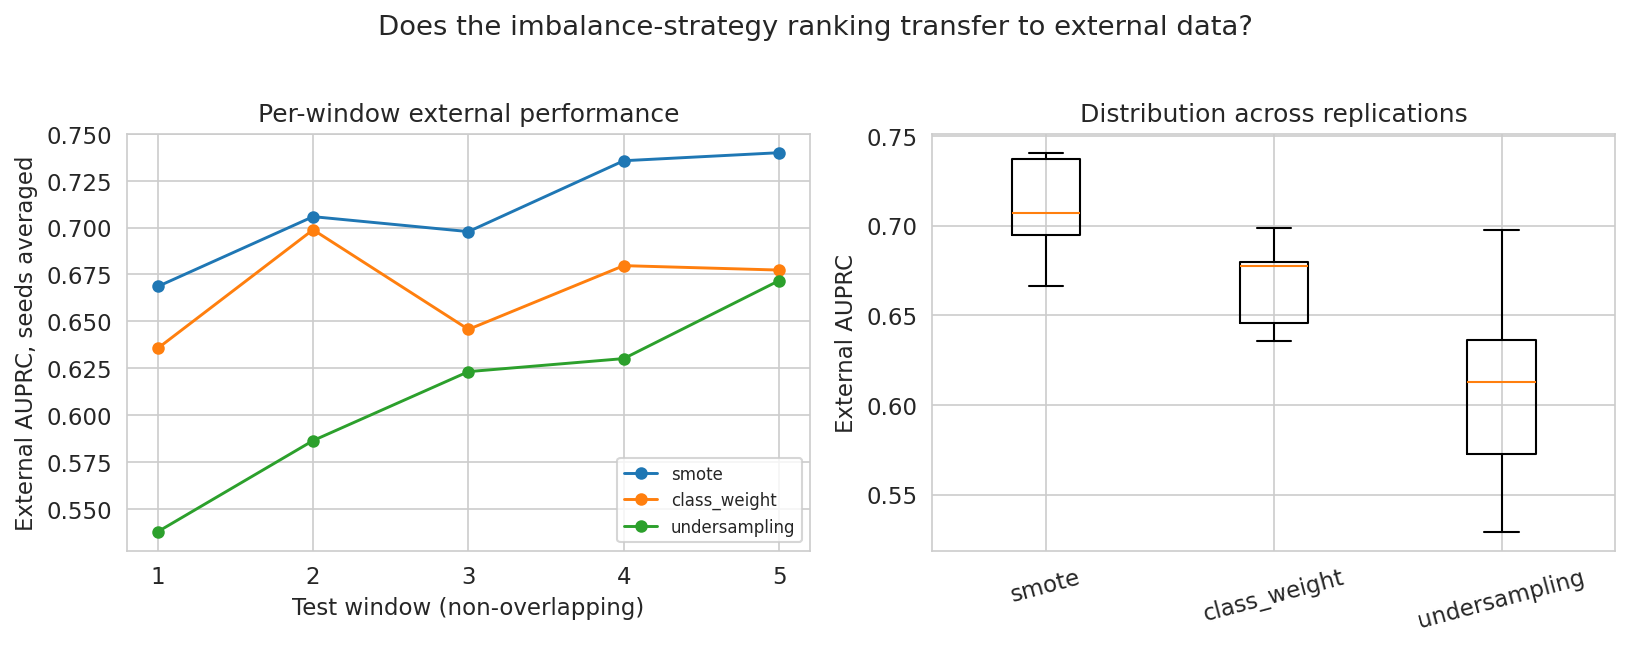


Exported external_replications.csv and external_window_means.csv


In [ ]:
if ext_rep_df is not None and len(ext_rep_df):
    ext_rep_df["Rank"] = ext_rep_df.groupby(["Origin", "Seed"])["AUPRC"] \
                                   .rank(ascending=False, method="min")
    n_reps = ext_rep_df.groupby(["Origin", "Seed"]).ngroups

    rep_summary = ext_rep_df.groupby("Strategy").agg(
        **{"Mean AUPRC": ("AUPRC", "mean"),
           "Std AUPRC": ("AUPRC", "std"),
           "Mean rank": ("Rank", "mean"),
           "Std rank": ("Rank", "std"),
           "Wins": ("Rank", lambda r: int((r == 1).sum())),
           "N reps": ("AUPRC", "size")}
    ).reset_index()
    rep_summary["Win rate"] = (rep_summary["Wins"] / n_reps).round(3)
    rep_summary = rep_summary.sort_values("Mean rank")

    print(f"Repeated external evaluation, {n_reps} replications per strategy "
          f"across {ext_rep_df['Origin'].nunique()} non-overlapping windows")
    print(rep_summary.round(4).to_string(index=False))

    ext_origin_df = (ext_rep_df.groupby(["Origin", "Strategy"])["AUPRC"]
                               .mean().reset_index())
    origin_pivot = ext_origin_df.pivot(index="Origin", columns="Strategy",
                                       values="AUPRC")
    print(f"\nPer-window mean AUPRC (seeds averaged within each window)")
    print(origin_pivot.round(4).to_string())

    ext_winner = rep_summary.iloc[0]["Strategy"]
    primary_base = str(best_strategy).replace("_tuned", "")

    if ext_winner in origin_pivot.columns and primary_base in origin_pivot.columns \
            and ext_winner != primary_base:
        a_o = origin_pivot[ext_winner].to_numpy(dtype=float)
        b_o = origin_pivot[primary_base].to_numpy(dtype=float)
        ok = ~(np.isnan(a_o) | np.isnan(b_o))
        a_o, b_o = a_o[ok], b_o[ok]
        diff_o = a_o - b_o
        n_o = len(diff_o)

        t_stat_o, t_p_o = scipy_stats.ttest_rel(a_o, b_o)
        try:
            _, w_p_o = scipy_stats.wilcoxon(a_o, b_o)
        except Exception:
            w_p_o = np.nan
        se_o = diff_o.std(ddof=1) / np.sqrt(n_o)
        tcrit_o = scipy_stats.t.ppf(0.975, n_o - 1)
        ci_lo_o = float(diff_o.mean() - tcrit_o * se_o)
        ci_hi_o = float(diff_o.mean() + tcrit_o * se_o)

        piv_rep = ext_rep_df.pivot_table(index=["Origin", "Seed"],
                                         columns="Strategy", values="AUPRC")
        a_r = piv_rep[ext_winner].to_numpy(dtype=float)
        b_r = piv_rep[primary_base].to_numpy(dtype=float)
        ok_r = ~(np.isnan(a_r) | np.isnan(b_r))
        diff_r = a_r[ok_r] - b_r[ok_r]
        winner_wins = int((diff_r > 0).sum())

        nontransfer_df = pd.DataFrame([{
            "Unit of analysis": "Non-overlapping windows (independent)",
            "N": n_o,
            "Mean AUPRC difference": round(float(diff_o.mean()), 4),
            "Std": round(float(diff_o.std(ddof=1)), 4),
            "95% CI low": round(ci_lo_o, 4),
            "95% CI high": round(ci_hi_o, 4),
            "Paired t-test p": round(float(t_p_o), 6),
            "Wilcoxon p": round(float(w_p_o), 6) if not np.isnan(w_p_o) else np.nan,
        }, {
            "Unit of analysis": "Origin x seed replications (correlated)",
            "N": len(diff_r),
            "Mean AUPRC difference": round(float(diff_r.mean()), 4),
            "Std": round(float(diff_r.std(ddof=1)), 4),
            "95% CI low": np.nan, "95% CI high": np.nan,
            "Paired t-test p": np.nan, "Wilcoxon p": np.nan,
        }])

        print(f"\nNon-transfer test: '{ext_winner}' (external winner) against "
              f"'{primary_base}' (primary-dataset winner)")
        print(nontransfer_df.to_string(index=False))
        print(f"\nWin rate: '{ext_winner}' beats '{primary_base}' in "
              f"{winner_wins} of {len(diff_r)} replications and in "
              f"{int((diff_o > 0).sum())} of {n_o} independent windows.")

        if n_o < 6:
            print(f"  Note: with {n_o} windows the two-sided Wilcoxon cannot "
                  f"fall below {2 / (2 ** n_o):.4f}, so read it as a "
                  f"consistency check and rely on the t-interval and the win "
                  f"rate for the strength of the claim.")

        if ci_lo_o > 0:
            print(f"\n  Non-transfer holds. '{ext_winner}' beats "
                  f"'{primary_base}' on external data with a 95% CI excluding "
                  f"zero across {n_o} disjoint test windows, so the estimate "
                  f"is not pseudo-replicated. The imbalance strategy selected "
                  f"on the primary benchmark is not the strategy that performs "
                  f"best on independently authored data under a "
                  f"deployment-realistic temporal protocol.")
        elif ci_hi_o < 0:
            print(f"\n  The primary-dataset winner also wins externally; the "
                  f"single-split reversal was an artefact of that one window.")
        else:
            print(f"\n  Inconclusive at n={n_o} windows: the CI spans zero. "
                  f"The defensible claim is that strategy selection is "
                  f"unstable across datasets, not that a specific reversal "
                  f"occurs. State it that way, and note that this is still "
                  f"incompatible with confident single-strategy "
                  f"recommendations.")
    else:
        print(f"\nThe external winner matches the primary-dataset winner; there "
              f"is no reversal to test.")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

    for strat in rep_summary["Strategy"]:
        sub = origin_pivot[strat]
        axes[0].plot(origin_pivot.index, sub.to_numpy(), "o-", ms=5, lw=1.4,
                     label=strat)
    axes[0].set_xlabel("Test window (non-overlapping)")
    axes[0].set_ylabel("External AUPRC, seeds averaged")
    axes[0].set_xticks(list(origin_pivot.index))
    axes[0].set_title("Per-window external performance")
    axes[0].legend(fontsize=8)

    order = rep_summary["Strategy"].tolist()
    axes[1].boxplot([ext_rep_df[ext_rep_df["Strategy"] == s]["AUPRC"].to_numpy()
                     for s in order])
    axes[1].set_xticklabels(order, rotation=15)
    axes[1].set_ylabel("External AUPRC")
    axes[1].set_title("Distribution across replications")

    plt.suptitle("Does the imbalance-strategy ranking transfer to external data?",
                 y=1.02)
    plt.tight_layout()
    plt.savefig("external_strategy_transfer.png", bbox_inches="tight")
    plt.show()

    ext_rep_df.to_csv("external_replications.csv", index=False)
    ext_origin_df.to_csv("external_window_means.csv", index=False)
    print("\nExported external_replications.csv and external_window_means.csv")
else:
    print("No external replications available to analyse.")

## Is strategy selection driven by the dataset or by its base rate?

The repeated external evaluation shows that the imbalance strategy chosen on
the primary benchmark is not the one that performs best on independently
authored data. Before that can be read as evidence about *datasets*, one
confound has to be addressed: the two corpora do not share a fraud
prevalence. The primary benchmark runs at roughly 0.17% fraud and the
external stream at roughly four times that, so a ranking that differs
between them might reflect the base rate rather than the data source.

Zuberi et al. raise exactly this possibility in their limitations, noting
that the relative ranking of oversampling strategies is plausibly sensitive
to prevalence, and leave it untested. Two complementary tests address it.
This section varies prevalence *within* the primary dataset; the next
section equalises prevalence *across* the two datasets.

Here the dataset, features, model family, protocol and evaluation set are
held fixed while genuine transactions are removed from the training
partition to raise the fraud rate through a grid of levels. Every condition
is scored against the same held-out transactions.

**Two design limits govern how this section may be read.** First, raising
prevalence by removing genuine rows also shrinks the training set — by
roughly thirty-fold across the grid — so a change at the high end of the
grid may reflect less training data as much as a higher base rate, and this
design cannot separate the two. Second, strategies are compared with a
paired confidence interval across seeds at each level, and a level counts as
a change in ranking only when that interval excludes zero. A difference in
mean AUPRC alone is not treated as a change in ranking.

The question this section answers for the external comparison is therefore
narrow: *at base rates like the external stream's, does the primary
benchmark's leading strategy still lead on the primary data?* If it does,
prevalence in that range cannot by itself explain why the leader loses
externally.


In [ ]:
PREVALENCE_GRID = [None, 0.005, 0.01, 0.02, 0.05]
PREV_SEEDS = 10
PREV_STRATEGIES = ["class_weight", "undersampling", "smote"] if HAS_IMBLEARN \
                  else ["class_weight"]

native_prev = float(y_train.mean())

PREVALENCE_GRID = [None] + [p for p in PREVALENCE_GRID
                            if p is not None and p > native_prev * 1.10]

print(f"Native training prevalence: {native_prev*100:.4f}%")
print(f"Grid retained (above native only): "
      + ", ".join("native" if p is None else f"{p*100:.1f}%"
                  for p in PREVALENCE_GRID))
print(f"Evaluation set held fixed: {len(y_test):,} transactions, "
      f"{int(y_test.sum())} frauds ({y_test.mean()*100:.4f}%)")
print(f"Grid: {len(PREVALENCE_GRID)} prevalence levels x "
      f"{len(PREV_STRATEGIES)} strategies x {PREV_SEEDS} seeds\n")


def subsample_to_prevalence(X_tr, y_tr, target_prev, seed):
    """Move the fraud rate to target_prev in either direction.

    Raising prevalence drops genuine rows; lowering it drops fraud rows.
    """
    if target_prev is None:
        return X_tr, y_tr
    y_arr = np.asarray(y_tr)
    fraud_idx = np.flatnonzero(y_arr == 1)
    genuine_idx = np.flatnonzero(y_arr == 0)
    n_f, n_g = len(fraud_idx), len(genuine_idx)
    if n_f == 0 or n_g == 0:
        return X_tr, y_tr
    current = n_f / (n_f + n_g)
    r = np.random.RandomState(seed)
    if target_prev > current:
        n_g_keep = int(round(n_f * (1 - target_prev) / target_prev))
        keep_g = r.choice(genuine_idx, size=min(n_g_keep, n_g), replace=False)
        keep = np.concatenate([fraud_idx, keep_g])
    elif target_prev < current:
        n_f_keep = max(1, int(round(n_g * target_prev / (1 - target_prev))))
        keep_f = r.choice(fraud_idx, size=min(n_f_keep, n_f), replace=False)
        keep = np.concatenate([keep_f, genuine_idx])
    else:
        return X_tr, y_tr
    keep = np.sort(keep)
    return X_tr.iloc[keep], y_tr.iloc[keep]


prev_rows = []
t_sweep = time.time()
for target in PREVALENCE_GRID:
    lvl = "native" if target is None else f"{target*100:.1f}%"
    for seed in [RANDOM_STATE + s for s in range(PREV_SEEDS)]:
        Xp, yp = subsample_to_prevalence(X_train, y_train, target, seed)
        achieved = float(yp.mean())
        for strat in PREV_STRATEGIES:
            try:
                Xr_, yr_ = build_strategy_training_set(Xp, yp, strat, seed)
                clf_ = instantiate_like(strat, best_name, yr_, seed)
                clf_.fit(Xr_, yr_)
                pr_ = clf_.predict_proba(X_test)[:, 1]
                prev_rows.append({
                    "Level": lvl,
                    "Achieved prevalence": achieved,
                    "Train rows": len(yp),
                    "Seed": seed,
                    "Strategy": strat,
                    "AUPRC": average_precision_score(y_test, pr_),
                    "ROC-AUC": roc_auc_score(y_test, pr_),
                })
            except Exception as e:
                print(f"  [{strat}] level {lvl} seed {seed} failed: {e}")

    done = [r for r in prev_rows if r["Level"] == lvl]
    if done:
        print(f"  level {lvl:>7s} ({done[0]['Achieved prevalence']*100:.3f}% "
              f"achieved, n={done[0]['Train rows']:,}): "
              + ", ".join(f"{s}={np.mean([r['AUPRC'] for r in done if r['Strategy'] == s]):.4f}"
                          for s in PREV_STRATEGIES))

prevalence_df = pd.DataFrame(prev_rows)
prevalence_df.to_csv("prevalence_controlled_ranking.csv", index=False)
print(f"\nSweep finished in {(time.time() - t_sweep)/60:.1f} min; "
      f"{len(prevalence_df)} fits exported to prevalence_controlled_ranking.csv")


Native training prevalence: 0.1667%
Grid retained (above native only): native, 0.5%, 1.0%, 2.0%, 5.0%
Evaluation set held fixed: 85,118 transactions, 142 frauds (0.1668%)
Grid: 5 prevalence levels x 3 strategies x 10 seeds

  level  native (0.167% achieved, n=198,608): class_weight=0.8179, undersampling=0.6470, smote=0.7920
  level    0.5% (0.500% achieved, n=66,200): class_weight=0.8061, undersampling=0.6748, smote=0.7894
  level    1.0% (1.000% achieved, n=33,100): class_weight=0.8015, undersampling=0.6494, smote=0.7863
  level    2.0% (2.000% achieved, n=16,550): class_weight=0.7967, undersampling=0.6723, smote=0.7791
  level    5.0% (5.000% achieved, n=6,620): class_weight=0.7690, undersampling=0.6686, smote=0.7634

Sweep finished in 9.3 min; 150 fits exported to prevalence_controlled_ranking.csv


Strategy performance against training-set fraud prevalence, evaluation set held fixed
 Level      Strategy  Achieved prevalence  Train rows  Mean AUPRC  Std AUPRC
native  class_weight               0.0017    198608.0      0.8179     0.0000
native         smote               0.0017    198608.0      0.7920     0.0045
native undersampling               0.0017    198608.0      0.6470     0.0430
  0.5%  class_weight               0.0050     66200.0      0.8061     0.0073
  0.5%         smote               0.0050     66200.0      0.7894     0.0097
  0.5% undersampling               0.0050     66200.0      0.6748     0.0322
  1.0%  class_weight               0.0100     33100.0      0.8015     0.0117
  1.0%         smote               0.0100     33100.0      0.7863     0.0069
  1.0% undersampling               0.0100     33100.0      0.6494     0.0486
  2.0%  class_weight               0.0200     16550.0      0.7967     0.0128
  2.0%         smote               0.0200     16550.0      0.7791  

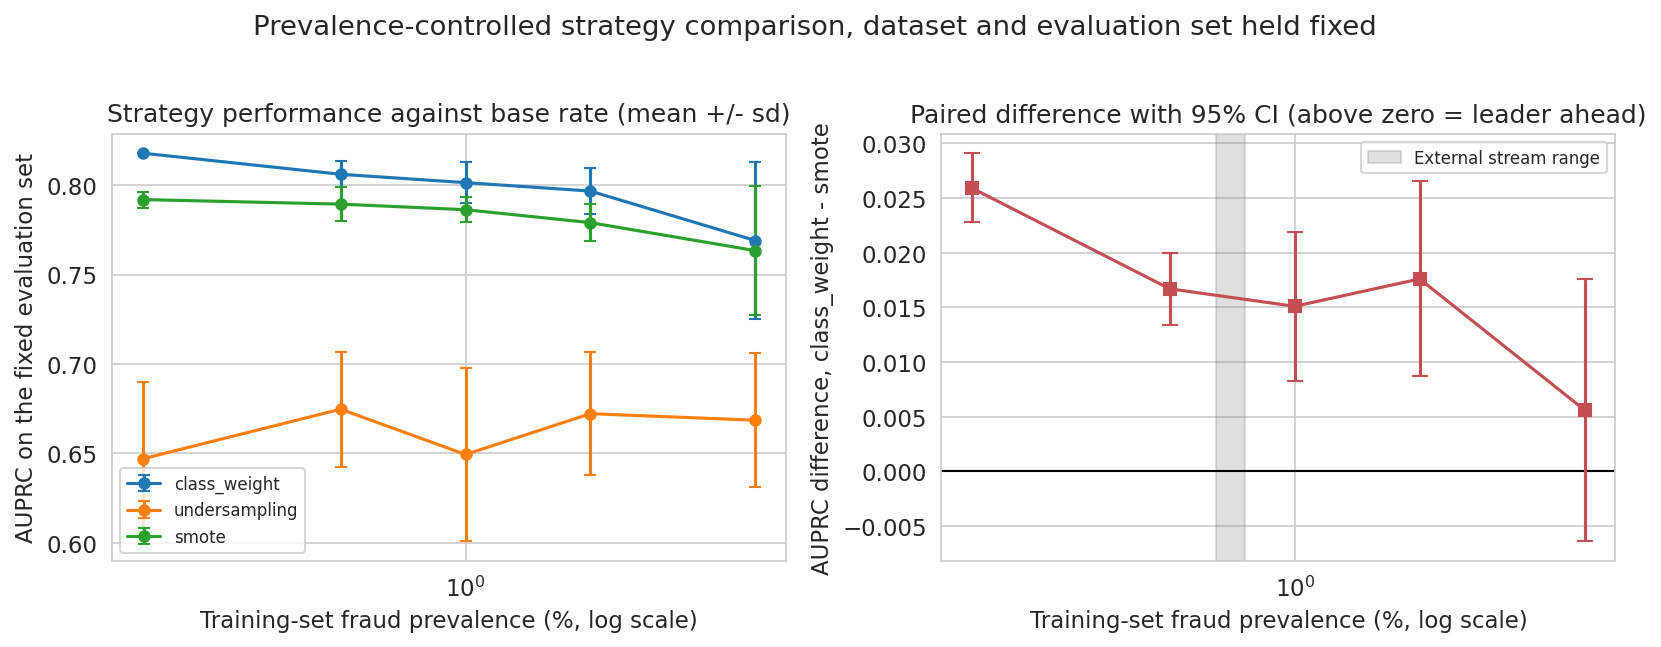


Exported prevalence_ranking_summary.csv and prevalence_paired_tests.csv


In [ ]:
level_order = (prevalence_df.groupby("Level")["Achieved prevalence"].mean()
               .sort_values().index.tolist())

prev_mean = (prevalence_df.groupby(["Level", "Strategy"])
             .agg(**{"Achieved prevalence": ("Achieved prevalence", "mean"),
                     "Train rows": ("Train rows", "mean"),
                     "Mean AUPRC": ("AUPRC", "mean"),
                     "Std AUPRC": ("AUPRC", "std")})
             .reset_index())
prev_mean["Level"] = pd.Categorical(prev_mean["Level"], level_order, ordered=True)
prev_mean = prev_mean.sort_values(["Level", "Mean AUPRC"], ascending=[True, False])

print("Strategy performance against training-set fraud prevalence, "
      "evaluation set held fixed")
print(prev_mean.round(4).to_string(index=False))

native_rank = prev_mean[prev_mean["Level"] == level_order[0]] \
    .sort_values("Mean AUPRC", ascending=False)["Strategy"].tolist()
leader, runner = native_rank[0], native_rank[1]

test_rows = []
for lvl in level_order:
    sub = prevalence_df[prevalence_df["Level"] == lvl]
    piv = sub.pivot_table(index="Seed", columns="Strategy", values="AUPRC")
    d = (piv[leader] - piv[runner]).dropna().to_numpy()
    n = len(d)
    m = float(d.mean())
    sd = float(d.std(ddof=1)) if n > 1 else 0.0
    if n > 1 and sd > 0:
        se = sd / np.sqrt(n)
        tc = scipy_stats.t.ppf(0.975, n - 1)
        lo, hi = m - tc * se, m + tc * se
        p = float(scipy_stats.ttest_1samp(d, 0.0).pvalue)
    else:
        lo = hi = m
        p = 0.0 if m != 0 else 1.0
    status = "leader ahead" if lo > 0 else ("reversed" if hi < 0 else "tie")
    test_rows.append({
        "Level": lvl,
        "Achieved prevalence (%)": round(100 * float(sub["Achieved prevalence"].mean()), 3),
        "Train rows": int(sub["Train rows"].mean()),
        f"{leader} - {runner}": round(m, 4),
        "95% CI low": round(lo, 4),
        "95% CI high": round(hi, 4),
        "t-test p": round(p, 4),
        "Seeds": n,
        "Status": status,
    })

prev_test_df = pd.DataFrame(test_rows)
print(f"\nPaired comparison of the native-level leader '{leader}' against "
      f"'{runner}' at each level ({PREV_SEEDS} seeds, paired by seed because "
      f"both strategies are trained on the same subsample)")
print(prev_test_df.to_string(index=False))

ahead = prev_test_df[prev_test_df["Status"] == "leader ahead"]
ties = prev_test_df[prev_test_df["Status"] == "tie"]
rev = prev_test_df[prev_test_df["Status"] == "reversed"]

print("\nInterpretation")
if len(rev):
    first_rev = rev.iloc[0]
    print(f"  The ranking reverses: '{runner}' beats '{leader}' at "
          f"{first_rev['Achieved prevalence (%)']:.3f}% fraud with a 95% CI "
          f"excluding zero. Changing the base rate alone, with the dataset "
          f"held fixed, reorders the strategies at that level.")
elif len(ties) == 0:
    print(f"  '{leader}' leads '{runner}' at every level from "
          f"{prev_test_df['Achieved prevalence (%)'].min():.3f}% to "
          f"{prev_test_df['Achieved prevalence (%)'].max():.3f}% fraud, each "
          f"with a 95% CI excluding zero. The ranking is stable across this "
          f"range of base rates.")
else:
    held = ahead["Achieved prevalence (%)"].tolist()
    tied = ties["Achieved prevalence (%)"].tolist()
    held_txt = (f"at {', '.join(f'{v:.3f}%' for v in held)}" if held
                else "at no level")
    print(f"  '{leader}' leads '{runner}' with a 95% CI excluding zero "
          f"{held_txt}. At {', '.join(f'{v:.3f}%' for v in tied)} the two "
          f"cannot be separated. No level shows a significant reversal, so "
          f"the evidence supports an advantage that narrows as prevalence "
          f"rises, not a change in ranking.")

n_max = int(prev_test_df["Train rows"].max())
n_min = int(prev_test_df["Train rows"].min())
print(f"  Design limit: raising prevalence here removes genuine transactions, "
      f"so training size falls from {n_max:,} to {n_min:,} rows across the "
      f"grid. Any narrowing or reversal at the high end may reflect the "
      f"smaller training set as much as the base rate, and this design does "
      f"not separate the two.")

ext_prev_range = None
try:
    if ext_ok and ext_windows:
        _vals = [float(ext_df.loc[ext_day < (s - DELAY_DAYS), "TX_FRAUD"].mean())
                 for s, _ in ext_windows]
        ext_prev_range = (min(_vals), max(_vals))
except NameError:
    ext_prev_range = None

prev_verdict = None
if ext_prev_range is not None:
    lo_p, hi_p = 100 * ext_prev_range[0], 100 * ext_prev_range[1]
    lv = prev_test_df["Achieved prevalence (%)"].to_numpy()
    lower_idx = int(np.flatnonzero(lv <= lo_p).max()) if (lv <= lo_p).any() else 0
    upper_idx = int(np.flatnonzero(lv >= hi_p).min()) if (lv >= hi_p).any() else len(lv) - 1
    bracket = prev_test_df.iloc[lower_idx:upper_idx + 1]
    br_txt = ", ".join(f"{r['Achieved prevalence (%)']:.3f}% ({r['Status']})"
                       for _, r in bracket.iterrows())
    print(f"\n  Link to the external comparison. The external training windows "
          f"run at {lo_p:.3f}%-{hi_p:.3f}% fraud. The grid levels bracketing "
          f"that range are: {br_txt}.")
    if (bracket["Status"] == "leader ahead").all():
        prev_verdict = "leader holds in external range"
        print(f"  On the primary data, '{leader}' still leads significantly at "
              f"base rates like the external stream's. Prevalence in that "
              f"range therefore cannot by itself explain why '{leader}' loses "
              f"on the external data. The matched-prevalence test that follows "
              f"checks the same question from the other direction.")
    else:
        prev_verdict = "leader weakened in external range"
        print(f"  On the primary data, '{leader}' no longer leads "
              f"significantly at every level in that range, so prevalence may "
              f"contribute to the external reversal. The matched-prevalence "
              f"test that follows addresses this directly and should be "
              f"treated as the decisive check.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for strat in PREV_STRATEGIES:
    s_ = prev_mean[prev_mean["Strategy"] == strat].sort_values("Achieved prevalence")
    axes[0].errorbar(s_["Achieved prevalence"] * 100, s_["Mean AUPRC"],
                     yerr=s_["Std AUPRC"].fillna(0), marker="o", ms=5,
                     lw=1.5, capsize=3, label=strat)
axes[0].set_xscale("log")
axes[0].set_xlabel("Training-set fraud prevalence (%, log scale)")
axes[0].set_ylabel("AUPRC on the fixed evaluation set")
axes[0].set_title("Strategy performance against base rate (mean +/- sd)")
axes[0].legend(fontsize=8)

x = prev_test_df["Achieved prevalence (%)"].to_numpy()
y_ = prev_test_df[f"{leader} - {runner}"].to_numpy()
err = np.vstack([y_ - prev_test_df["95% CI low"].to_numpy(),
                 prev_test_df["95% CI high"].to_numpy() - y_])
axes[1].axhline(0, color="black", lw=1)
axes[1].errorbar(x, y_, yerr=err, marker="s", ms=6, lw=1.5, capsize=4,
                 color="#C44E52")
if ext_prev_range is not None:
    axes[1].axvspan(100 * ext_prev_range[0], 100 * ext_prev_range[1],
                    color="grey", alpha=0.25, label="External stream range")
    axes[1].legend(fontsize=8)
axes[1].set_xscale("log")
axes[1].set_xlabel("Training-set fraud prevalence (%, log scale)")
axes[1].set_ylabel(f"AUPRC difference, {leader} - {runner}")
axes[1].set_title("Paired difference with 95% CI (above zero = leader ahead)")

plt.suptitle("Prevalence-controlled strategy comparison, dataset and "
             "evaluation set held fixed", y=1.02)
plt.tight_layout()
plt.savefig("prevalence_controlled_ranking.png", bbox_inches="tight")
plt.show()

prev_mean.to_csv("prevalence_ranking_summary.csv", index=False)
prev_test_df.to_csv("prevalence_paired_tests.csv", index=False)
print("\nExported prevalence_ranking_summary.csv and prevalence_paired_tests.csv")


## The external comparison repeated at matched prevalence

The prevalence sweep above varies the base rate within one dataset. This
section closes the loop from the other direction: it repeats the external
evaluation with the external stream thinned to the primary benchmark's fraud
rate, so that the two corpora are compared at the same prevalence rather than
at their native rates.

Genuine transactions are removed from each external training window until its
fraud rate matches the primary training partition. The test windows are left
at their native composition, because thinning them would change what the
model is scored against and make the AUPRC values incomparable to the earlier
run. The windows, the delay period, the seeds and the strategies are
otherwise identical to the native-prevalence run, so the two sets of numbers
differ in exactly one respect.

If the external winner is unchanged after matching, the reversal survives the
only confound that plausibly explained it away. If the winner changes, the
earlier result was at least partly a base-rate effect and must be reported as
such.


Thinning each external training window to the primary benchmark's fraud rate of 0.1667%

  origin 1: train n=248,856 at 0.1668% fraud (was 250,000 at 0.6236%), test days 42-51 unchanged
  origin 2: train n=248,718 at 0.1669% fraud (was 250,000 at 0.6788%), test days 52-61 unchanged
  origin 3: train n=248,609 at 0.1665% fraud (was 250,000 at 0.7220%), test days 62-71 unchanged
  origin 4: train n=248,566 at 0.1666% fraud (was 250,000 at 0.7392%), test days 72-81 unchanged
  origin 5: train n=248,517 at 0.1666% fraud (was 250,000 at 0.7588%), test days 82-91 unchanged

Prevalence-matching check: largest relative deviation from the 0.1667% target across windows = 0.12%
  PASS: every external training window was moved to the primary benchmark's base rate, so the comparison below differs from the native run in prevalence alone.

External evaluation at matched prevalence
     Strategy  Mean AUPRC  Std across windows  Windows won
        smote      0.6576              0.0289            5
 cl

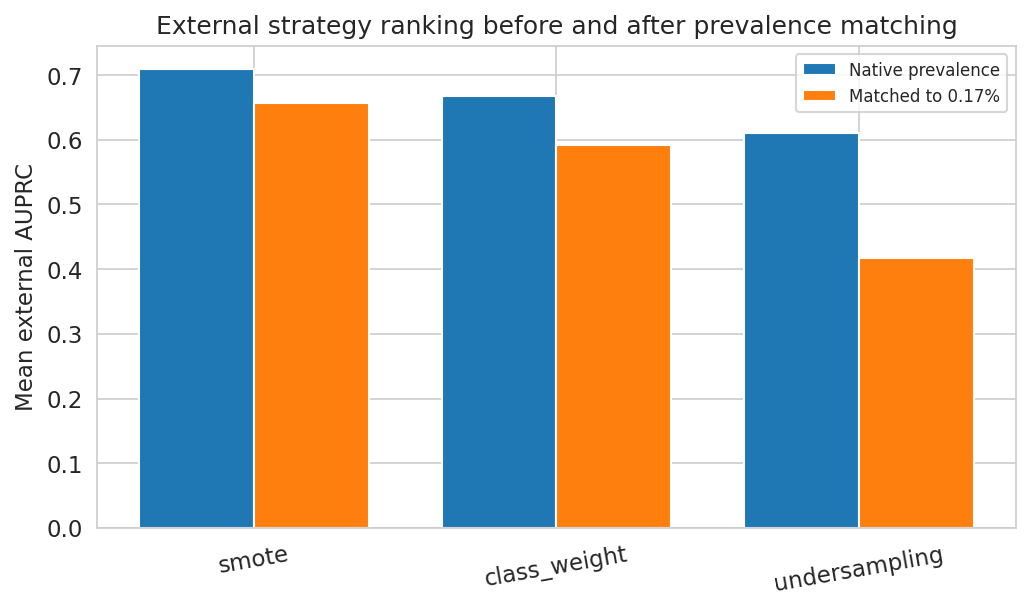


Exported external_matched_prevalence.csv and external_native_vs_matched.csv


In [ ]:
ext_matched_df = None

if ext_rep_df is not None and len(ext_rep_df) and ext_ok:
    target_prev = float(y_train.mean())
    print(f"Thinning each external training window to the primary benchmark's "
          f"fraud rate of {target_prev*100:.4f}%\n")

    matched_rows = []
    match_dev = []
    for o_i, (te_start, te_end) in enumerate(ext_windows, start=1):
        tr_end = te_start - DELAY_DAYS
        m_tr = ext_day < tr_end
        m_te = (ext_day >= te_start) & (ext_day < te_end)

        Xo_tr_raw = ext_df.loc[m_tr, ext_feats].reset_index(drop=True)
        Xo_te_raw = ext_df.loc[m_te, ext_feats].reset_index(drop=True)
        yo_tr = ext_df.loc[m_tr, "TX_FRAUD"].astype(int).reset_index(drop=True)
        yo_te = ext_df.loc[m_te, "TX_FRAUD"].astype(int).reset_index(drop=True)

        if len(yo_tr) > EXT_SUBSAMPLE:
            keep = np.random.RandomState(RANDOM_STATE).choice(
                len(yo_tr), EXT_SUBSAMPLE, replace=False)
            Xo_tr_raw, yo_tr = Xo_tr_raw.iloc[keep], yo_tr.iloc[keep]

        Xo_tr_m, yo_tr_m = subsample_to_prevalence(
            Xo_tr_raw, yo_tr, target_prev, RANDOM_STATE + o_i)
        match_dev.append(abs(float(yo_tr_m.mean()) - target_prev) / target_prev)

        sc_cols = [c for c in ext_feats if ext_df[c].dtype.kind == "f"]
        sc_ = RobustScaler().fit(Xo_tr_m[sc_cols])
        Xo_tr_s, Xo_te_s = Xo_tr_m.copy(), Xo_te_raw.copy()
        Xo_tr_s[sc_cols] = sc_.transform(Xo_tr_m[sc_cols])
        Xo_te_s[sc_cols] = sc_.transform(Xo_te_raw[sc_cols])

        print(f"  origin {o_i}: train n={len(yo_tr_m):,} at "
              f"{yo_tr_m.mean()*100:.4f}% fraud "
              f"(was {len(yo_tr):,} at {yo_tr.mean()*100:.4f}%), "
              f"test days {te_start}-{te_end-1} unchanged")

        for seed in [RANDOM_STATE + s for s in range(N_EXT_SEEDS)]:
            for strat in ext_strategies:
                try:
                    Xr_, yr_ = build_strategy_training_set(
                        Xo_tr_s, yo_tr_m, strat, seed)
                    clf_ = instantiate_like(strat, best_name, yr_, seed)
                    clf_.fit(Xr_, yr_)
                    pr_ = clf_.predict_proba(Xo_te_s)[:, 1]
                    matched_rows.append({
                        "Origin": o_i, "Seed": seed, "Strategy": strat,
                        "AUPRC": average_precision_score(yo_te, pr_),
                        "ROC-AUC": roc_auc_score(yo_te, pr_),
                    })
                except Exception as e:
                    print(f"    [{strat}] seed {seed} failed: {e}")

    ext_matched_df = pd.DataFrame(matched_rows)

    max_dev = max(match_dev) if match_dev else float("nan")
    matching_ok = bool(match_dev) and max_dev <= 0.10
    print(f"\nPrevalence-matching check: largest relative deviation from the "
          f"{target_prev*100:.4f}% target across windows = {max_dev:.2%}")
    if matching_ok:
        print("  PASS: every external training window was moved to the primary "
              "benchmark's base rate, so the comparison below differs from the "
              "native run in prevalence alone.")
    else:
        print("  FAIL: at least one window could not be moved to the target "
              "prevalence. The comparison would not isolate prevalence, so no "
              "conclusion is drawn from it.")

    if len(ext_matched_df) and matching_ok:
        matched_origin = (ext_matched_df.groupby(["Origin", "Strategy"])["AUPRC"]
                          .mean().reset_index())
        matched_summary = (matched_origin.groupby("Strategy")["AUPRC"]
                           .agg(["mean", "std"]).reset_index()
                           .rename(columns={"mean": "Mean AUPRC",
                                            "std": "Std across windows"}))
        matched_origin["Rank"] = matched_origin.groupby("Origin")["AUPRC"] \
                                               .rank(ascending=False, method="min")
        wins_m = (matched_origin[matched_origin["Rank"] == 1]["Strategy"]
                  .value_counts())
        matched_summary["Windows won"] = matched_summary["Strategy"].map(
            wins_m).fillna(0).astype(int)
        matched_summary = matched_summary.sort_values("Mean AUPRC",
                                                      ascending=False)

        print("\nExternal evaluation at matched prevalence")
        print(matched_summary.round(4).to_string(index=False))

        native_summary = (ext_origin_df.groupby("Strategy")["AUPRC"].mean()
                          .reset_index().rename(columns={"AUPRC": "Native AUPRC"}))
        compare = native_summary.merge(
            matched_summary[["Strategy", "Mean AUPRC"]].rename(
                columns={"Mean AUPRC": "Matched AUPRC"}), on="Strategy")
        compare["Delta"] = compare["Matched AUPRC"] - compare["Native AUPRC"]
        compare["Native rank"] = compare["Native AUPRC"].rank(ascending=False,
                                                              method="min")
        compare["Matched rank"] = compare["Matched AUPRC"].rank(ascending=False,
                                                                method="min")
        compare = compare.sort_values("Matched rank")

        print("\nNative against matched prevalence, same windows and seeds")
        print(compare.round(4).to_string(index=False))

        native_winner = compare.sort_values("Native rank")["Strategy"].iloc[0]
        primary_base = str(best_strategy).replace("_tuned", "")

        print("\nInterpretation")
        print(f"  External winner at native prevalence : {native_winner}")
        print(f"  Primary-benchmark winner             : {primary_base}")

        piv_m = matched_origin.pivot(index="Origin", columns="Strategy",
                                     values="AUPRC")
        if native_winner == primary_base or not {native_winner, primary_base} \
                <= set(piv_m.columns):
            print("\n  No reversal to test: the native external winner matches "
                  "the primary-benchmark winner.")
        else:
            d = (piv_m[native_winner] - piv_m[primary_base]).dropna().to_numpy()
            n_w = len(d)
            mean_d = float(d.mean())
            if n_w > 1:
                se = d.std(ddof=1) / np.sqrt(n_w)
                tcrit = scipy_stats.t.ppf(0.975, n_w - 1)
                lo, hi = mean_d - tcrit * se, mean_d + tcrit * se
                t_p = float(scipy_stats.ttest_1samp(d, 0.0).pvalue)
            else:
                lo = hi = t_p = float("nan")

            print(f"\n  Paired test at matched prevalence, '{native_winner}' "
                  f"minus '{primary_base}' across {n_w} disjoint windows:")
            print(f"    mean AUPRC difference = {mean_d:+.4f}, "
                  f"95% CI [{lo:+.4f}, {hi:+.4f}], t p = {t_p:.4f}, "
                  f"windows won = {int((d > 0).sum())} of {n_w}")

            if lo > 0:
                print(f"\n  The reversal survives prevalence matching. "
                      f"'{native_winner}' still beats '{primary_base}' on "
                      f"external data at the primary benchmark's base rate, "
                      f"with a 95% CI excluding zero. The non-transfer cannot "
                      f"be attributed to the prevalence difference between "
                      f"the two corpora.")
            elif hi < 0:
                print(f"\n  The reversal is overturned by prevalence matching: "
                      f"at matched base rates '{primary_base}' beats "
                      f"'{native_winner}' with a 95% CI excluding zero. The "
                      f"native-prevalence reversal was a base-rate effect, "
                      f"not evidence about the data source, and must be "
                      f"reported that way.")
            else:
                print(f"\n  Inconclusive at matched prevalence: the 95% CI "
                      f"spans zero. Once the base rates are equalised the two "
                      f"strategies cannot be separated at n={n_w} windows, so "
                      f"the native-prevalence reversal is at least partly a "
                      f"base-rate effect. Report the non-transfer as jointly "
                      f"driven by data source and prevalence rather than by "
                      f"data source alone.")

        fig, ax = plt.subplots(figsize=(7, 4.2))
        idx = np.arange(len(compare))
        w = 0.38
        ax.bar(idx - w/2, compare["Native AUPRC"], w, label="Native prevalence")
        ax.bar(idx + w/2, compare["Matched AUPRC"], w,
               label=f"Matched to {target_prev*100:.2f}%")
        ax.set_xticks(idx)
        ax.set_xticklabels(compare["Strategy"], rotation=10)
        ax.set_ylabel("Mean external AUPRC")
        ax.set_title("External strategy ranking before and after prevalence matching")
        ax.legend(fontsize=8)
        plt.tight_layout()
        plt.savefig("external_prevalence_matched.png", bbox_inches="tight")
        plt.show()

        ext_matched_df.to_csv("external_matched_prevalence.csv", index=False)
        compare.to_csv("external_native_vs_matched.csv", index=False)
        print("\nExported external_matched_prevalence.csv and "
              "external_native_vs_matched.csv")
else:
    print("Matched-prevalence external evaluation skipped, no external "
          "replications available.")


## Synthetic stress test

The simulator below is written inside this notebook, so it cannot evidence
external generalisation. It is retained only as a stress test of the pipeline
against a different rare-event generating process, and its absolute numbers
are not comparable with the real data.

In [ ]:
def simulate_transactions(n_customers=2000, n_terminals=400, n_days=30,
                          seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    records = []

    customer_mean_amount = rng.uniform(20, 100, size=n_customers)
    customer_std_amount = customer_mean_amount * 0.3
    customer_tx_per_day = rng.uniform(0.5, 4, size=n_customers)

    compromised_terminals = []
    compromised_customers = []

    for day in range(n_days):
        for _ in range(2):
            compromised_terminals.append((rng.randint(0, n_terminals), day, day + 28))
        for _ in range(3):
            compromised_customers.append((rng.randint(0, n_customers), day, day + 14))

        for cust in range(n_customers):
            for _ in range(rng.poisson(customer_tx_per_day[cust])):
                terminal = rng.randint(0, n_terminals)
                tx_time = day * 86400 + rng.randint(0, 86400)
                amount = max(0.01, rng.normal(customer_mean_amount[cust],
                                              customer_std_amount[cust]))
                is_fraud = 0

                if amount > 220 and rng.rand() < 0.03:
                    is_fraud = 1

                for term_id, start, end in compromised_terminals:
                    if terminal == term_id and start <= day <= end:
                        is_fraud = 1
                        break

                for cust_id, start, end in compromised_customers:
                    if cust == cust_id and start <= day <= end and rng.rand() < 0.33:
                        amount *= 5
                        is_fraud = 1
                        break

                records.append((cust, terminal, tx_time, round(amount, 2), is_fraud))

    return pd.DataFrame(records, columns=["customer_id", "terminal_id",
                                          "tx_time_seconds", "amount", "fraud"])


t0 = time.time()
sim_df = simulate_transactions()
print(f"Simulated {len(sim_df):,} transactions in {time.time() - t0:.1f}s")
print(f"Simulated fraud rate: {sim_df['fraud'].mean() * 100:.3f}% "
      f"({int(sim_df['fraud'].sum())} of {len(sim_df):,})")
sim_df.head()

Simulated 134,343 transactions in 1.8s
Simulated fraud rate: 8.039% (10800 of 134,343)


,customer_id,terminal_id,tx_time_seconds,amount,fraud
0,0,385,35733,48.79,0
1,0,355,16428,48.63,0
2,0,274,64140,30.57,0
3,1,37,63928,60.49,0
4,2,4,25491,89.59,0


In [ ]:
sim_df = sim_df.sort_values("tx_time_seconds").reset_index(drop=True)
sim_df["cust_running_mean_amount"] = (
    sim_df.groupby("customer_id")["amount"]
          .transform(lambda s: s.expanding().mean().shift(1))
).fillna(sim_df["amount"].mean())
sim_df["amount_vs_cust_mean"] = sim_df["amount"] / (sim_df["cust_running_mean_amount"] + 1e-6)
sim_df["terminal_tx_count"] = sim_df.groupby("terminal_id")["terminal_id"].transform("count")

sim_features = ["amount", "tx_time_seconds", "cust_running_mean_amount",
                "amount_vs_cust_mean", "terminal_tx_count"]
X_sim, y_sim = sim_df[sim_features].copy(), sim_df["fraud"]

X_sim_train_raw, X_sim_test_raw, y_sim_train, y_sim_test = train_test_split(
    X_sim, y_sim, test_size=0.30, stratify=y_sim, random_state=RANDOM_STATE)

sim_scale_cols = ["amount", "tx_time_seconds"]
sim_scaler = RobustScaler().fit(X_sim_train_raw[sim_scale_cols])
X_sim_train, X_sim_test = X_sim_train_raw.copy(), X_sim_test_raw.copy()
X_sim_train[sim_scale_cols] = sim_scaler.transform(X_sim_train_raw[sim_scale_cols])
X_sim_test[sim_scale_cols] = sim_scaler.transform(X_sim_test_raw[sim_scale_cols])

print(f"Simulated train/test: {X_sim_train.shape} / {X_sim_test.shape}, "
      f"train fraud rate {y_sim_train.mean() * 100:.3f}%")

sim_model = instantiate_like("class_weight", best_name, y_sim_train, RANDOM_STATE)
t0 = time.time()
sim_model.fit(X_sim_train, y_sim_train)
sim_fit_time = time.time() - t0

sim_proba = sim_model.predict_proba(X_sim_test)[:, 1]
sim_pred = (sim_proba >= 0.5).astype(int)

sim_auprc = average_precision_score(y_sim_test, sim_proba)
sim_rocauc = roc_auc_score(y_sim_test, sim_proba)
sim_f1 = f1_score(y_sim_test, sim_pred, zero_division=0)

print(f"\nSynthetic stress test, {best_name} with class weighting retrained "
      f"from scratch")
print(f"  AUPRC   = {sim_auprc:.4f}")
print(f"  ROC-AUC = {sim_rocauc:.4f}")
print(f"  F1      = {sim_f1:.4f}")
print(f"  fit time {sim_fit_time:.1f}s")
print(f"\nThese values describe a different generating process and must not be "
      f"placed beside the real-data numbers as evidence that performance "
      f"holds up.")

Simulated train/test: (94040, 5) / (40303, 5), train fraud rate 8.039%

Synthetic stress test, XGBoost with class weighting retrained from scratch
  AUPRC   = 0.5177
  ROC-AUC = 0.9116
  F1      = 0.3869
  fit time 1.3s

These values describe a different generating process and must not be placed beside the real-data numbers as evidence that performance holds up.


In [ ]:
def _fmt_p(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


def _plural(n, one, many):
    return f"{n} {one if n == 1 else many}"


n_neg = int(auprc_stat["Negative origins"])
wil_p = float(auprc_stat["Wilcoxon p"])
t_p_roll = float(auprc_stat["t-test p"])

parts = []
parts.append(f"""
Both unsupervised baselines trail the best supervised model by a wide margin
(Isolation Forest AUPRC = {iforest_auprc:.4f}, autoencoder AUPRC =
{ae_auprc:.4f}, against {best_row['AUPRC']:.4f} for {best_name} /
{best_strategy}), confirming that label information carries substantial value
on this feature space even though the task is naturally framed as anomaly
detection.

CS-Stack reaches AUPRC = {stack_auprc:.4f} on the same held-out test set, a
change of {stack_gain:+.4f} against the best individual model, with a Brier
score of {stack_brier:.6f} against {best_brier:.6f}. It is reported as a
negative result.
""")

wil_note = ""
if t_p_roll < 0.05 <= wil_p:
    min_wil = 2.0 / 2 ** len(rolling_df)
    wil_note = (f" The effect is significant under the paired t-test "
                f"(p {_fmt_p(t_p_roll)}) but borderline under the Wilcoxon "
                f"signed-rank test (p {_fmt_p(wil_p)}); with "
                f"{len(rolling_df)} origins the smallest attainable two-sided "
                f"Wilcoxon p-value is {min_wil:.3f}, and both tests are "
                f"reported.")

parts.append(f"""
The two protocol findings are the substance of this study. Random-split
optimism measured across {len(rolling_df)} prevalence-matched, non-overlapping
rolling origins is {auprc_stat['Mean optimism']:+.4f} AUPRC (95% CI
[{auprc_stat['95% CI low']:+.4f}, {auprc_stat['95% CI high']:+.4f}],
{_plural(n_neg, 'origin', 'origins')} reversing sign), while the matching
ROC-AUC optimism is {roc_stat['Mean optimism']:+.4f} and indistinguishable
from zero.{wil_note}
""")

try:
    nt = nontransfer_df.iloc[0]
    parts.append(f"""
On independently authored data, evaluated over
{int(nt['N'])} non-overlapping temporal windows, '{ext_winner}' outperforms
the primary benchmark's selected strategy '{primary_base}' by
{nt['Mean AUPRC difference']:+.4f} AUPRC (95% CI [{nt['95% CI low']:+.4f},
{nt['95% CI high']:+.4f}], paired t-test p {_fmt_p(float(nt['Paired t-test p']))}).
The strategy selected on the benchmark does not transfer.
""")
except (NameError, KeyError, IndexError):
    pass

try:
    mo = (ext_matched_df.groupby(["Origin", "Strategy"])["AUPRC"].mean()
          .unstack("Strategy"))
    dm = (mo[ext_winner] - mo[primary_base]).dropna().to_numpy() \
        if ext_winner != primary_base else np.array([])
    if len(dm) > 1 and dm.std(ddof=1) > 0:
        se_m = dm.std(ddof=1) / np.sqrt(len(dm))
        tc_m = scipy_stats.t.ppf(0.975, len(dm) - 1)
        lo_m, hi_m = dm.mean() - tc_m * se_m, dm.mean() + tc_m * se_m
        p_m = float(scipy_stats.ttest_1samp(dm, 0.0).pvalue)
        if lo_m > 0:
            verdict = ("The reversal therefore survives prevalence matching "
                       "and cannot be attributed to the difference in base "
                       "rate between the two corpora.")
        elif hi_m < 0:
            verdict = ("The reversal is overturned by prevalence matching and "
                       "should be read as a base-rate effect.")
        else:
            verdict = ("Once base rates are equalised the two strategies "
                       "cannot be separated, so the reversal is at least "
                       "partly a base-rate effect.")
        parts.append(f"""
When every external training window is thinned to the primary benchmark's
fraud rate, the same comparison gives {dm.mean():+.4f} AUPRC (95% CI
[{lo_m:+.4f}, {hi_m:+.4f}], paired t-test p {_fmt_p(p_m)}, '{ext_winner}'
ahead in {int((dm > 0).sum())} of {len(dm)} windows). {verdict}
""")
except (NameError, KeyError, AttributeError):
    pass

try:
    tied_levels = prev_test_df[prev_test_df["Status"] != "leader ahead"]
    if prev_verdict == "leader holds in external range":
        link = ("At base rates like the external stream's, the benchmark's "
                "selected strategy still leads on the benchmark itself, which "
                "is consistent with the matched-prevalence result.")
    elif prev_verdict == "leader weakened in external range":
        link = ("At base rates like the external stream's, the benchmark's "
                "selected strategy no longer leads significantly on the "
                "benchmark itself, so prevalence may contribute to the "
                "reversal.")
    else:
        link = ""
    if len(tied_levels):
        tail = (f"Its advantage narrows as prevalence rises and cannot be "
                f"distinguished from zero at "
                f"{', '.join(f'{v:.3f}%' for v in tied_levels['Achieved prevalence (%)'])} "
                f"fraud, where the training set is also much smaller; this "
                f"design does not separate the two effects.")
    else:
        tail = "Its advantage holds at every level of the grid."
    parts.append(f"""
Varying prevalence within the benchmark, with the evaluation set held fixed,
shows the selected strategy leading its nearest competitor with a 95% CI
excluding zero at
{_plural(int((prev_test_df['Status'] == 'leader ahead').sum()), 'level', 'levels')}
of {len(prev_test_df)}. {tail} {link}
""")
except NameError:
    pass

addendum = "\n".join(p.strip() + "\n" for p in parts)
display(Markdown(addendum))


Both unsupervised baselines trail the best supervised model by a wide margin
(Isolation Forest AUPRC = 0.1083, autoencoder AUPRC =
0.2593, against 0.8334 for XGBoost /
class_weight_tuned), confirming that label information carries substantial value
on this feature space even though the task is naturally framed as anomaly
detection.

CS-Stack reaches AUPRC = 0.8245 on the same held-out test set, a
change of -0.0089 against the best individual model, with a Brier
score of 0.001540 against 0.000408. It is reported as a
negative result.

The two protocol findings are the substance of this study. Random-split
optimism measured across 6 prevalence-matched, non-overlapping
rolling origins is +0.1000 AUPRC (95% CI
[+0.0173, +0.1827],
1 origin reversing sign), while the matching
ROC-AUC optimism is -0.0102 and indistinguishable
from zero. The effect is significant under the paired t-test (p = 0.027) but borderline under the Wilcoxon signed-rank test (p = 0.062); with 6 origins the smallest attainable two-sided Wilcoxon p-value is 0.031, and both tests are reported.

On independently authored data, evaluated over
5 non-overlapping temporal windows, 'smote' outperforms
the primary benchmark's selected strategy 'class_weight' by
+0.0421 AUPRC (95% CI [+0.0142,
+0.0701], paired t-test p = 0.014).
The strategy selected on the benchmark does not transfer.

When every external training window is thinned to the primary benchmark's
fraud rate, the same comparison gives +0.0652 AUPRC (95% CI
[+0.0417, +0.0888], paired t-test p = 0.002, 'smote'
ahead in 5 of 5 windows). The reversal therefore survives prevalence matching and cannot be attributed to the difference in base rate between the two corpora.

Varying prevalence within the benchmark, with the evaluation set held fixed,
shows the selected strategy leading its nearest competitor with a 95% CI
excluding zero at
4 levels
of 5. Its advantage narrows as prevalence rises and cannot be distinguished from zero at 5.000% fraud, where the training set is also much smaller; this design does not separate the two effects. At base rates like the external stream's, the benchmark's selected strategy still leads on the benchmark itself, which is consistent with the matched-prevalence result.


## References

- A. Dal Pozzolo, O. Caelen, R. A. Johnson and G. Bontempi, "Calibrating
  probability with undersampling for unbalanced classification," *Proc. IEEE
  Symp. Computational Intelligence and Data Mining*, 2015.
- A. Dal Pozzolo, O. Caelen, Y.-A. Le Borgne, S. Waterschoot and G. Bontempi,
  "Learned lessons in credit card fraud detection from a practitioner
  perspective," *Expert Systems with Applications*, 2014.
- Y.-A. Le Borgne and G. Bontempi, *Reproducible Machine Learning for Credit
  Card Fraud Detection: Practical Handbook*, Université Libre de Bruxelles.
- A. C. Bahnsen, D. Aouada and B. Ottersten, "Example-dependent cost-sensitive
  logistic regression for credit scoring," *Proc. ICMLA*, 2014.
- N. V. Chawla, K. W. Bowyer, L. O. Hall and W. P. Kegelmeyer, "SMOTE:
  synthetic minority over-sampling technique," *Journal of Artificial
  Intelligence Research*, 2002.
- T. Saito and M. Rehmsmeier, "The precision-recall plot is more informative
  than the ROC plot when evaluating binary classifiers on imbalanced
  datasets," *PLOS ONE*, 2015.
- S. Holm, "A simple sequentially rejective multiple test procedure,"
  *Scandinavian Journal of Statistics*, 1979.
- F. T. Liu, K. M. Ting and Z.-H. Zhou, "Isolation forest," *Proc. IEEE ICDM*,
  2008.
- D. H. Wolpert, "Stacked generalization," *Neural Networks*, 1992.
- C. Bergmeir and J. M. Benítez, "On the use of cross-validation for time
  series predictor evaluation," *Information Sciences*, 2012.
- N. Zuberi, M. M. Rahman, S. U. Rashid, M. N. Ahsan, M. S. Rahman and
  M. H. O. R. Mollah, "A robust machine learning framework for detecting
  temporal drift in financial fraud prevention," *Scientific Reports*, vol. 16,
  Art. no. 27776, 2026.
- K. Hayat and B. Magnier, "Data leakage and deceptive performance: A critical
  examination of credit card fraud detection methodologies," *Mathematics*,
  vol. 13, Art. no. 2563, 2025.
- S. Kapoor and A. Narayanan, "Leakage and the reproducibility crisis in
  machine-learning-based science," *Patterns*, vol. 4, no. 9, Art. no. 100804,
  2023.
